# Simulación de un brazo robótico plano de tres articulaciones
**Tecnológico de Costa Rica**

**Escuela de matemática**

**Curso:**
Métodos numéricos

**Laboratorio 1:**
Simulación de un brazo robótico plano de tres articulaciones

**Profesor:**
Jeffry Chavarría Molina


**Estudiantes:**

Alberto Alfredo Quiros Cordero

Jared Alberto Segura Elizondo

Luis Daniel Corrales Mora

Verónica Muñoz Zúñiga

Nicole Valverde Chacón

**II Semestre**

**Año:**
2026

## Objetivo
Implementar la cinemática directa, la interpolación articular y la representación gráfica del recorrido de un brazo robótico plano 3R. Generar animaciones, tablas de resultados y figuras comparativas para las secuencias y opciones auxiliares establecidas en el enunciado.

## Dependencias
NumPy, pandas, Matplotlib y Pillow. La exportación de animaciones us `PillowWriter`.


## 5. Modelo geométrico del brazo robótico

El brazo se modela en un plano y está formado por tres eslabones rígidos de longitudes positivas $l_1$, $l_2$ y $l_3$. Su base permanece fija en el origen $O=(0,0)$. Las articulaciones permiten modificar los ángulos relativos $\theta_1$, $\theta_2$ y $\theta_3$. El extremo del tercer eslabón se denomina efector final.

Para cada problema se conocen las longitudes y las coordenadas del punto objetivo $(x,y)$. Las incógnitas son los tres ángulos articulares. El modelo del enunciado no introduce límites articulares ni restricciones por colisión.

| Símbolo | Significado |
|---|---|
| $l_1,l_2,l_3$ | Longitudes de los eslabones |
| $(x,y)$ | Coordenadas del punto objetivo |
| $\theta_1$ | Orientación del primer eslabón respecto al eje horizontal positivo |
| $\theta_2$ | Giro del segundo eslabón respecto a la dirección del primero |
| $\theta_3$ | Giro del tercer eslabón respecto a la dirección del segundo |

Los ángulos se calculan en radianes. La conversión a grados se realiza mediante

$$\theta_{\mathrm{grados}}=\theta_{\mathrm{radianes}}\frac{180}{\pi}.$$

### 5.1. Orientaciones absolutas y coordenadas

Las orientaciones de los eslabones respecto al eje horizontal son acumulativas:

$$\varphi_1=\theta_1,\qquad \varphi_2=\theta_1+\theta_2,\qquad \varphi_3=\theta_1+\theta_2+\theta_3.$$

Por ejemplo, para $(\theta_1,\theta_2,\theta_3)=(30^\circ,20^\circ,-10^\circ)$, las orientaciones absolutas son $30^\circ$, $50^\circ$ y $40^\circ$.

Un eslabón de longitud $l$ y orientación $\varphi$ aporta el vector $(l\cos\varphi,l\sin\varphi)$. Sumando esos vectores se obtienen las posiciones de las articulaciones y del efector:

$$A=(l_1\cos\theta_1,\ l_1\sin\theta_1),$$

$$W=A+(l_2\cos(\theta_1+\theta_2),\ l_2\sin(\theta_1+\theta_2)),$$

$$P=W+(l_3\cos(\theta_1+\theta_2+\theta_3),\ l_3\sin(\theta_1+\theta_2+\theta_3)).$$

La letra $W$ representa la muñeca, es decir, la articulación que une el segundo y el tercer eslabón. En adelante se denota la posición calculada del efector por $(X(\boldsymbol\theta),Y(\boldsymbol\theta))$, para distinguirla del objetivo conocido $(x,y)$:

$$X(\boldsymbol\theta)=l_1\cos\theta_1+l_2\cos(\theta_1+\theta_2)+l_3\cos(\theta_1+\theta_2+\theta_3),$$

$$Y(\boldsymbol\theta)=l_1\sin\theta_1+l_2\sin(\theta_1+\theta_2)+l_3\sin(\theta_1+\theta_2+\theta_3).$$

Estos cálculos constituyen la cinemática directa. En el problema inverso se busca una configuración $\boldsymbol\theta$ para la cual $X(\boldsymbol\theta)=x$ y $Y(\boldsymbol\theta)=y$.

### 5.2. Postura inicial y alcance geométrico

La postura articular inicial y final requerida es

$$\boldsymbol\theta=(0,0,0).$$

En esa postura, los tres eslabones están extendidos hacia la derecha y el efector se encuentra en

$$P=(l_1+l_2+l_3,0).$$

Para los experimentos obligatorios, $l_1=l_2=l_3=1$, por lo que esta posición es $(3,0)$.

Sin imponer una ecuación auxiliar, el alcance radial de un brazo con giros libres satisface

$$r_{\min}\leq r=\sqrt{x^2+y^2}\leq r_{\max},$$

$$r_{\max}=l_1+l_2+l_3,\qquad r_{\min}=\max\{0,\ 2\max(l_1,l_2,l_3)-(l_1+l_2+l_3)\}.$$

La cota inferior aparece cuando el eslabón más largo excede la suma de los otros dos: aun plegando el brazo, estos no pueden compensar toda su longitud. En los experimentos de eslabones unitarios, $r_{\min}=0$ y el alcance general es el disco $r\leq3$. Para longitudes arbitrarias, comprobar únicamente la cota exterior puede omitir puntos situados dentro del hueco interior.

## 6. Planteamiento de los cinco sistemas no lineales

Las ecuaciones de posición dan dos condiciones para tres incógnitas. En una configuración regular queda un grado de libertad: distintas posturas pueden alcanzar el mismo punto. La ecuación auxiliar agrega una condición sobre los ángulos y selecciona determinadas posturas. Su incorporación no garantiza una solución única ni asegura que todo punto del alcance general continúe siendo compatible.

Se definen los residuos de posición

$$F_1(\boldsymbol\theta)=X(\boldsymbol\theta)-x,$$

$$F_2(\boldsymbol\theta)=Y(\boldsymbol\theta)-y.$$

Con $\varphi_3=\theta_1+\theta_2+\theta_3$, los cinco sistemas son

$$\mathbf F^{(A)}(\boldsymbol\theta)=\begin{pmatrix}F_1\\F_2\\\theta_1+\theta_2+\theta_3\end{pmatrix}=\mathbf0,$$

$$\mathbf F^{(B)}(\boldsymbol\theta)=\begin{pmatrix}F_1\\F_2\\\theta_1+\theta_2+\theta_3-\pi/2\end{pmatrix}=\mathbf0,$$

$$\mathbf F^{(C)}(\boldsymbol\theta)=\begin{pmatrix}F_1\\F_2\\\theta_3\end{pmatrix}=\mathbf0,$$

$$\mathbf F^{(D)}(\boldsymbol\theta)=\begin{pmatrix}F_1\\F_2\\\theta_2-\theta_3\end{pmatrix}=\mathbf0,$$

$$\mathbf F^{(E)}(\boldsymbol\theta)=\begin{pmatrix}F_1\\F_2\\\theta_1+\theta_2+\theta_3-\alpha(x,y)-\pi/2\end{pmatrix}=\mathbf0.$$

Aquí se utiliza la convención del enunciado

$$\alpha(x,y)=\begin{cases}\operatorname{atan2}(y,x),&(x,y)\neq(0,0),\\0,&(x,y)=(0,0).\end{cases}$$

Se resuelve un sistema por opción. Las cinco ecuaciones auxiliares no se imponen simultáneamente.

### 6.1. Interpretación geométrica de las opciones

| Opción | Condición | Interpretación |
|---|---|---|
| A | $\varphi_3=0$ | El tercer eslabón apunta horizontalmente hacia la derecha. |
| B | $\varphi_3=\pi/2$ | El tercer eslabón apunta verticalmente hacia arriba. |
| C | $\theta_3=0$ | El tercer eslabón prolonga al segundo en la misma dirección. |
| D | $\theta_2=\theta_3$ | Los giros relativos de la segunda y tercera articulación son iguales. |
| E | $\varphi_3=\alpha(x,y)+\pi/2$ | El tercer eslabón apunta en la dirección tangencial antihoraria respecto al segmento del origen al objetivo. |

En D, igualar los ángulos relativos no significa igualar las orientaciones absolutas de los dos últimos eslabones. En E, sumar $\pi/2$ escoge una de las dos direcciones perpendiculares posibles.

Los ángulos se interpretan módulo $2\pi$. Los sistemas escritos utilizan representantes concretos de esas condiciones. Para trabajar con otras ramas equivalentes puede elegirse un múltiplo entero de $2\pi$, manteniéndolo fijo durante cada resolución y documentándolo. La evaluación del residuo angular debe ser coherente con la rama elegida.

### 6.2. Alcance compatible con cada condición

En A, B y E, para un objetivo fijo está determinada la dirección del último eslabón. La muñeca debe ubicarse en

$$W=P-l_3(\cos\varphi_3,\sin\varphi_3).$$

Los primeros dos eslabones pueden alcanzar esa muñeca si y solo si

$$|l_1-l_2|\leq\|W\|\leq l_1+l_2.$$

Para $l_1=l_2=1$, la cota inferior es cero. Por eso, en A, B y E se puede utilizar directamente $\|W\|\leq2$. El criterio necesita la cota inferior cuando las primeras dos longitudes son distintas.

En C y D, la dirección final depende de relaciones entre ángulos que también restringen la postura de los eslabones anteriores. Comprobar una muñeca que sea alcanzable por un brazo de dos eslabones, sin imponer esas relaciones, no demuestra compatibilidad con C o D. Sus criterios se derivan en la Fase II.

### 6.3. Continuidad y tratamiento de atan2

La función $\operatorname{atan2}(y,x)$ identifica el cuadrante de la dirección del objetivo. Al cruzar su corte en el eje horizontal negativo, el valor principal puede pasar de un ángulo cercano a $\pi$ a otro cercano a $-\pi$. Las direcciones físicas son próximas, aunque las representaciones numéricas difieran casi $2\pi$.

En E se puede desenvolver la secuencia de ángulos polares, o elegir para cada nuevo objetivo un representante $\alpha+2\pi m$ cercano al anterior. Esta elección conserva la dirección tangencial y ayuda a evitar vueltas artificiales. También deben tratarse de forma coherente los representantes de los tres ángulos articulares.

En el origen no existe una dirección radial ni tangencial única. La convención $\alpha(0,0)=0$ impone $\varphi_3=\pi/2$ en ese objetivo. Para eslabones unitarios el origen sigue siendo compatible con E, porque su muñeca es $(0,-1)$ y tiene distancia $1$. Sin embargo, esa elección no proporciona continuidad desde todas las direcciones de aproximación al origen.

Usar la solución del punto anterior como suposición inicial ayuda a mantener la misma rama de soluciones, aunque no garantiza continuidad en todos los casos. Para convertir los ángulos a un intervalo principal debe cuidarse que el cambio de representación no introduzca saltos en la animación ni altere la interpretación del residuo.

Las ecuaciones auxiliares se usan para calcular las configuraciones de los puntos objetivo. La postura de reposo $(0,0,0)$, exigida para el inicio y el regreso, satisface A, C y D, pero no satisface B ni E en la posición inicial $(3,0)$. Las transiciones de entrada y regreso deben permitir ese cambio de orientación. Además, interpolar ángulos entre dos soluciones de E no asegura que todos los puntos intermedios del efector mantengan la condición tangencial respecto a su posición instantánea.

## 7. Construcción de los cinco jacobianos

El jacobiano contiene las derivadas de las tres ecuaciones respecto a las tres incógnitas:

$$J^{(s)}(\boldsymbol\theta)=\begin{pmatrix}\dfrac{\partial F_1}{\partial\theta_1}&\dfrac{\partial F_1}{\partial\theta_2}&\dfrac{\partial F_1}{\partial\theta_3}\\\dfrac{\partial F_2}{\partial\theta_1}&\dfrac{\partial F_2}{\partial\theta_2}&\dfrac{\partial F_2}{\partial\theta_3}\\\dfrac{\partial F_3^{(s)}}{\partial\theta_1}&\dfrac{\partial F_3^{(s)}}{\partial\theta_2}&\dfrac{\partial F_3^{(s)}}{\partial\theta_3}\end{pmatrix}.$$

El punto $(x,y)$ y las longitudes se mantienen constantes al derivar.

### 7.1. Derivación de las ecuaciones de posición

Se utilizan $d(\cos u)/d\theta=-\sin u\,du/d\theta$ y $d(\sin u)/d\theta=\cos u\,du/d\theta$. Los argumentos $\theta_1+\theta_2$ y $\theta_1+\theta_2+\theta_3$ tienen derivada $1$ respecto a cada ángulo que contienen.

Por ejemplo, al derivar $F_1$ respecto a $\theta_2$, el primer término es constante y los otros dos aportan

$$\frac{\partial F_1}{\partial\theta_2}=0-l_2\sin(\theta_1+\theta_2)\cdot1-l_3\sin(\theta_1+\theta_2+\theta_3)\cdot1.$$

Las seis derivadas de posición son

$$\frac{\partial F_1}{\partial\theta_1}=-l_1\sin\theta_1-l_2\sin(\theta_1+\theta_2)-l_3\sin(\theta_1+\theta_2+\theta_3),$$

$$\frac{\partial F_1}{\partial\theta_2}=-l_2\sin(\theta_1+\theta_2)-l_3\sin(\theta_1+\theta_2+\theta_3),$$

$$\frac{\partial F_1}{\partial\theta_3}=-l_3\sin(\theta_1+\theta_2+\theta_3),$$

$$\frac{\partial F_2}{\partial\theta_1}=l_1\cos\theta_1+l_2\cos(\theta_1+\theta_2)+l_3\cos(\theta_1+\theta_2+\theta_3),$$

$$\frac{\partial F_2}{\partial\theta_2}=l_2\cos(\theta_1+\theta_2)+l_3\cos(\theta_1+\theta_2+\theta_3),$$

$$\frac{\partial F_2}{\partial\theta_3}=l_3\cos(\theta_1+\theta_2+\theta_3).$$

### 7.2. Derivación de las ecuaciones auxiliares

En A, B y E, cada ángulo aparece con coeficiente $1$. Sus constantes tienen derivada cero. En particular, $\alpha(x,y)$ es constante durante la resolución de un objetivo de E: se calcula con las coordenadas conocidas del objetivo, no con las coordenadas que produzca una iteración intermedia.

| Opción | $\partial F_3/\partial\theta_1$ | $\partial F_3/\partial\theta_2$ | $\partial F_3/\partial\theta_3$ |
|---|---|---|---|
| A | 1 | 1 | 1 |
| B | 1 | 1 | 1 |
| C | 0 | 0 | 1 |
| D | 0 | 1 | -1 |
| E | 1 | 1 | 1 |

### 7.3. Matrices resultantes

Para presentar las matrices sin repetir expresiones largas, se definen

$$s_1=l_1\sin\theta_1,\quad s_2=l_2\sin(\theta_1+\theta_2),\quad s_3=l_3\sin(\theta_1+\theta_2+\theta_3),$$

$$c_1=l_1\cos\theta_1,\quad c_2=l_2\cos(\theta_1+\theta_2),\quad c_3=l_3\cos(\theta_1+\theta_2+\theta_3).$$

Los cinco jacobianos quedan explícitamente como

$$J^{(A)}=\begin{pmatrix}-(s_1+s_2+s_3)&-(s_2+s_3)&-s_3\\c_1+c_2+c_3&c_2+c_3&c_3\\1&1&1\end{pmatrix},$$

$$J^{(B)}=\begin{pmatrix}-(s_1+s_2+s_3)&-(s_2+s_3)&-s_3\\c_1+c_2+c_3&c_2+c_3&c_3\\1&1&1\end{pmatrix},$$

$$J^{(C)}=\begin{pmatrix}-(s_1+s_2+s_3)&-(s_2+s_3)&-s_3\\c_1+c_2+c_3&c_2+c_3&c_3\\0&0&1\end{pmatrix},$$

$$J^{(D)}=\begin{pmatrix}-(s_1+s_2+s_3)&-(s_2+s_3)&-s_3\\c_1+c_2+c_3&c_2+c_3&c_3\\0&1&-1\end{pmatrix},$$

$$J^{(E)}=\begin{pmatrix}-(s_1+s_2+s_3)&-(s_2+s_3)&-s_3\\c_1+c_2+c_3&c_2+c_3&c_3\\1&1&1\end{pmatrix}.$$

Por tanto, $J^{(A)}$, $J^{(B)}$ y $J^{(E)}$ son iguales si se evalúan en la misma configuración angular. Sus sistemas y soluciones pueden ser diferentes, porque sus terceras ecuaciones contienen constantes distintas.

### 7.4. Singularidades

Una configuración es singular para este sistema cuando $\det J=0$. El sistema lineal de Newton puede entonces carecer de una corrección única. Cerca de una singularidad también puede producir correcciones grandes y sensibles a errores numéricos.

Para las primeras, segunda y quinta opciones,

$$\det J^{(A)}=\det J^{(B)}=\det J^{(E)}=l_1l_2\sin\theta_2.$$

La singularidad aparece cuando los primeros dos eslabones son colineales. En el alcance de la muñeca de eslabones unitarios ocurre en su frontera exterior $\|W\|=2$ y también en el centro $W=(0,0)$, donde los primeros dos eslabones pueden cancelarse en diferentes orientaciones.

Para C, al evaluar sobre la condición $\theta_3=0$,

$$\det J^{(C)}=l_1(l_2+l_3)\sin\theta_2.$$

Con eslabones unitarios, los extremos radiales $r=1$ y $r=3$ corresponden a configuraciones singulares.

Para D, el determinante general es

$$\det J^{(D)}=-\left[l_1l_2\sin\theta_2+2l_1l_3\sin(\theta_2+\theta_3)+l_2l_3\sin\theta_3\right].$$

Con $l_1=l_2=l_3=1$ y $\theta_2=\theta_3=t$, se reduce a

$$\det J^{(D)}=-2\sin t\,(1+2\cos t).$$

Esta opción presenta singularidades tanto en la frontera exterior como en algunas posturas interiores. En particular, las configuraciones que llegan al origen tienen $1+2\cos t=0$ y son singulares, aunque el origen sea compatible.

En $(\theta_1,\theta_2,\theta_3)=(0,0,0)$, la primera fila del jacobiano es cero para todas las opciones. Esto explica por qué la postura inicial de la animación no debe obligar a usar esa misma configuración como primera suposición de Newton-Raphson.

Una singularidad describe una dificultad local del método. Por sí sola no prueba que el objetivo sea geométricamente imposible.

## 8. Newton-Raphson aplicado al problema

Newton-Raphson busca una raíz de $\mathbf F^{(s)}(\boldsymbol\theta)=\mathbf0$ mediante aproximaciones sucesivas. Se parte de una suposición $\boldsymbol\theta^{(0)}$ y se aproxima el sistema alrededor de la configuración actual:

$$\mathbf F^{(s)}(\boldsymbol\theta^{(k)}+\Delta\boldsymbol\theta^{(k)})\approx\mathbf F^{(s)}(\boldsymbol\theta^{(k)})+J^{(s)}(\boldsymbol\theta^{(k)})\Delta\boldsymbol\theta^{(k)}.$$

Para que la aproximación sea cero, se resuelve el sistema lineal

$$J^{(s)}(\boldsymbol\theta^{(k)})\Delta\boldsymbol\theta^{(k)}=-\mathbf F^{(s)}(\boldsymbol\theta^{(k)}),$$

y después se actualizan simultáneamente los tres ángulos:

$$\boldsymbol\theta^{(k+1)}=\boldsymbol\theta^{(k)}+\Delta\boldsymbol\theta^{(k)}.$$

La corrección tiene tres componentes y modifica las tres incógnitas en una misma iteración. En Python conviene resolver el sistema lineal directamente, por ejemplo mediante `numpy.linalg.solve`, en lugar de construir explícitamente la inversa del jacobiano.

### 8.1. Suposición inicial y continuidad entre puntos

Para el primer punto se necesita una suposición cuyo jacobiano sea no singular. Una propuesta inicial es $(0.15,0.25,-0.15)$ radianes, que deberá confirmarse o sustituirse según la implementación y las pruebas del equipo. La animación conserva su inicio obligatorio en $(0,0,0)$, independientemente de la suposición numérica.

Para los puntos siguientes se utiliza, siempre que sea posible, la última solución válida. Si esa suposición falla, se pueden probar otras y documentar los intentos. Encontrar una solución mediante varias suposiciones mejora la evidencia numérica, pero no garantiza que todos los intentos converjan ni que todos alcancen la misma postura.

### 8.2. Residuo y criterio de convergencia

El residuo exigido para comparar las ejecuciones es

$$R(\boldsymbol\theta)=\|\mathbf F^{(s)}(\boldsymbol\theta)\|_2=\sqrt{F_1^2+F_2^2+(F_3^{(s)})^2}.$$

Un residuo pequeño indica que la configuración satisface aproximadamente las tres ecuaciones. Conviene comprobar también el error de posición

$$e_P=\sqrt{(X(\boldsymbol\theta)-x)^2+(Y(\boldsymbol\theta)-y)^2},$$

y el tamaño de la corrección

$$e_\theta=\|\Delta\boldsymbol\theta\|_\infty=\max_i|\Delta\theta_i|.$$

El criterio de convergencia por residuo se cumple cuando el residuo de la configuración actualizada es menor o igual que $\varepsilon_F$. El tamaño del paso ayuda a detectar estabilización o estancamiento; si el paso es pequeño y el residuo continúa siendo grande, no se ha verificado una solución.


### 8.3. Diagnóstico de la ejecución

Se distingue entre los siguientes resultados:

| Estado | Justificación |
|---|---|
| Éxito | Se encontró una configuración que satisface el criterio de residuo y las verificaciones correspondientes. |
| Fuera del alcance geométrico | El objetivo viola el alcance radial del brazo, incluso antes de imponer la ecuación auxiliar. |
| Incompatible | El objetivo está en el alcance general, pero una condición geométrica demuestra que no cumple el alcance de la opción. Las pruebas numéricas complementan ese diagnóstico. |
| No converge | Los intentos realizados no satisfacen la tolerancia; esto puede ocurrir aun cuando exista una solución compatible. |

Al superar el máximo de iteraciones, encontrar un jacobiano singular o producir valores no finitos, el intento debe reportar su situación y continuar con la estrategia acordada. Esos fallos no justifican por sí mismos el estado «incompatible».

Para cada objetivo se deben reportar la opción, los ángulos en radianes y grados, el número de iteraciones, el residuo final y el estado. Los residuos deben evaluarse con representantes angulares coherentes con las ecuaciones; reducir cada ángulo por separado a un intervalo principal puede cambiar una suma angular en un múltiplo de $2\pi$ sin cambiar la postura física.

Los parámetros utilizados en la implementación de Newton-Raphson son los siguientes:

| Parámetro | Valor utilizado |
|---|---|
| Criterio de convergencia | $\lVert\mathbf F^{(s)}(\boldsymbol\theta)\rVert_2\leq10^{-10}$ |
| Máximo de iteraciones | 50 por intento |
| Primera suposición | $(0.15,0.25,-0.15)$ radianes |
| Criterio de singularidad | $\lvert\det J\rvert<10^{-12}$ |
| Criterio de estancamiento | $\lVert\Delta\boldsymbol\theta\rVert_\infty<10^{-15}$ cuando el residuo todavía supera la tolerancia |

En cada iteración se resuelve el sistema lineal $J\Delta\boldsymbol\theta=-\mathbf F$ mediante `numpy.linalg.solve` y se actualizan simultáneamente los tres ángulos.

Para los objetivos posteriores se utiliza la última solución aceptada como suposición inicial. Si un intento falla, el programa prueba la suposición por defecto y dieciséis suposiciones adicionales, generadas mediante el mismo procedimiento para las cinco opciones.

La singularidad, el estancamiento, los valores no finitos o el agotamiento de las iteraciones interrumpen un intento. Si todos los intentos fallan, los criterios geométricos permiten distinguir entre un punto fuera del alcance, uno incompatible con la opción y uno compatible para el cual el método no convergió.

La simulación realiza una validación adicional del residuo y del error de posición con tolerancia $10^{-8}$.

## Parámetros de simulación

| Parámetro | Valor |
|---|---|
| Longitudes de los eslabones | $l_1=l_2=l_3=1$ |
| Cuadros de movimiento por tramo | 40 |
| Frecuencia de reproducción | 20 fps |
| Pausa en cada objetivo | 10 cuadros, equivalentes a 0.5 s |
| Suposición inicial del primer objetivo | $(0.15,0.25,-0.15)$ rad |
| Tolerancia de validación de resultados | $10^{-8}$ |
| Directorio de salida | `resultados_luis` |

La tolerancia de validación comprueba el residuo recibido y el error de posición. La tolerancia de Newton-Raphson, el máximo de iteraciones y la estrategia de reintentos se establecen en `NR_Un_Punto` y deben ser iguales para las cinco opciones.

Ante un punto no alcanzado, se conserva la última configuración válida, se identifica el objetivo con una X roja y se continúa con el siguiente punto. Se mantienen el orden de visita y el diagnóstico devuelto por el método numérico.

La configuración inicial y final es $(\theta_1,\theta_2,\theta_3)=(0,0,0)$. Su posición cartesiana es $(l_1+l_2+l_3,0)$, equivalente a $(3,0)$ en los experimentos.


## 9. Cinemática directa e interpolación

Las posiciones se calculan acumulando las orientaciones de los eslabones:
\[
J_1=(l_1\cos\theta_1,l_1\sin\theta_1),\quad
J_2=J_1+l_2(\cos(\theta_1+\theta_2),\sin(\theta_1+\theta_2)),
\]
\[
P=J_2+l_3(\cos(\theta_1+\theta_2+\theta_3),\sin(\theta_1+\theta_2+\theta_3)).
\]

Para moverse entre objetivos se toma la diferencia mínima de cada ángulo módulo $2\pi$ y se interpolan los tres con el mismo parámetro $s(u)=3u^2-2u^3$. Esto da velocidad angular cero en los extremos y evita giros artificiales al cruzar $\pm\pi$.

En el **último tramo** se interpola hasta los valores literales $(0,0,0)$, sin hacer un reinicio brusco. Si hubo acumulación de vueltas, ese regreso puede ser más largo que el giro mínimo. Las condiciones auxiliares se exigen en los objetivos resueltos; la interpolación articular no impone que cada posición intermedia satisfaga la condición auxiliar, particularmente en E.


In [ ]:
"""Cinemática, simulación y representación gráfica de un brazo plano 3R."""
from pathlib import Path
import inspect
import json
import numpy as np
import pandas as pd

P = [(1.5, 0.5), (0.5, 1.5), (-0.5, 1.2), (1.2, -0.5)]
Q = [(0.5, 0.5), (1.3, 1.3), (-1.4, 0.3), (0.3, -1.4)]
OPCIONES = tuple("ABCDE")
CUADROS_POR_TRAMO = 40
FPS = 20
PAUSA_CUADROS = 10
TOL_VALIDACION = 1e-8
SEMILLA_INICIAL = np.array([0.15, 0.25, -0.15])
CARPETA = Path("resultados_luis")
# Nombre del argumento opcional de suposición inicial de NR_Un_Punto.
PARAMETRO_SEMILLA = "theta0"


def _longitudes(l1, l2, l3):
    L = np.array([l1, l2, l3], dtype=float)
    if not np.all(np.isfinite(L)) or np.any(L <= 0):
        raise ValueError("Las tres longitudes deben ser positivas y finitas.")
    return L


def cinematica_directa(l1, l2, l3, theta):
    """Devuelve base, articulación 1, articulación 2 y efector: arreglo (4, 2).

    Los ángulos son relativos, en radianes. Las orientaciones absolutas
    de los eslabones son th1, th1+th2 y th1+th2+th3.
    """
    L = _longitudes(l1, l2, l3)
    t = np.asarray(theta, dtype=float)
    if t.shape != (3,) or not np.all(np.isfinite(t)):
        raise ValueError("theta debe contener tres ángulos finitos en radianes.")
    a = np.cumsum(t)
    vectores = L[:, None] * np.column_stack((np.cos(a), np.sin(a)))
    return np.vstack((np.zeros(2), np.cumsum(vectores, axis=0)))


def interpolar_angulos(inicio, destino, cuadros=CUADROS_POR_TRAMO,
                       vuelta_exacta=False):
    """Interpola los tres ángulos a la vez con velocidad cero en los extremos.

    Entre objetivos usa la diferencia mínima módulo 2*pi. En el regreso
    usa el destino literal (0,0,0), sin reiniciar bruscamente los ángulos.
    Devuelve cuadros+1 posturas, incluidos ambos extremos.
    """
    a, b = np.asarray(inicio, float), np.asarray(destino, float)
    if a.shape != (3,) or b.shape != (3,):
        raise ValueError("Se necesitan tres ángulos por postura.")
    if not np.all(np.isfinite([a, b])):
        raise ValueError("Los ángulos deben ser finitos.")
    if not isinstance(cuadros, (int, np.integer)) or cuadros < 2:
        raise ValueError("cuadros debe ser un entero de al menos 2.")
    delta = b - a if vuelta_exacta else (b - a + np.pi) % (2*np.pi) - np.pi
    u = np.linspace(0, 1, cuadros + 1)
    suavizado = 3*u*u - 2*u*u*u
    posturas = a + suavizado[:, None] * delta
    if vuelta_exacta:
        posturas[-1] = b  # Cero exacto, tras un movimiento continuo.
    return posturas


def longitud_trayectoria(xy):
    """Longitud poligonal aproximada; depende del muestreo de la animación."""
    return float(np.linalg.norm(np.diff(np.asarray(xy), axis=0), axis=1).sum())


def sigma_min_cinematica(l1, l2, l3, theta):
    """Menor valor singular del jacobiano de POSICIÓN (2x3), no del sistema 3x3."""
    L = _longitudes(l1, l2, l3)
    a = np.cumsum(theta)
    sx = L * np.sin(a)
    cy = L * np.cos(a)
    Jp = np.array([[-sx[j:].sum() for j in range(3)],
                   [cy[j:].sum() for j in range(3)]])
    return float(np.linalg.svd(Jp, compute_uv=False)[-1])


### Verificación de la cinemática y la interpolación
Se comprueban dos configuraciones conocidas y una transición angular a través del corte de ±π.


In [ ]:
assert np.allclose(cinematica_directa(1, 1, 1, [0, 0, 0]),
                   [[0, 0], [1, 0], [2, 0], [3, 0]])
assert np.allclose(cinematica_directa(1, 1, 1, [np.pi/2, 0, 0])[-1], [0, 3])
prueba = interpolar_angulos(np.deg2rad([179, 0, 0]), np.deg2rad([-179, 0, 0]))
assert np.isclose(np.rad2deg(prueba[-1, 0] - prueba[0, 0]), 2)
print("Cinemática directa e interpolación: comprobaciones correctas.")


Cinemática directa e interpolación: comprobaciones correctas.


### Función principal y contrato de conexión

`Laboratorio_Brazo_3AR(l1,l2,l3,puntos,opcion)` usa `NR_Un_Punto` del espacio de trabajo. También admite el argumento opcional `solver=...`.

El solver debe aceptar una semilla externa y devolver:
```python
{
    "punto": (x, y), "opcion": "A",
    "theta_rad": np.array([th1, th2, th3]),  # None cuando falla
    "theta_deg": np.array([...]),           # None cuando falla
    "iteraciones": k, "residuo": normF,
    "estado": "exito",  # o fuera_alcance / incompatible / no_converge
    "mensaje": "..."
}
```
La función comprueba que un éxito tenga ángulos finitos, grados consistentes, residuo aceptable y posición correcta mediante cinemática directa. Un error de interfaz interrumpe la ejecución con un mensaje; no se oculta como incompatibilidad.

Las filas de las tablas conservan los ángulos originales del solver. Las columnas `anim_theta*_rad` contienen las representaciones equivalentes utilizadas por la animación. El solver recibe como próxima semilla su última solución válida original.


In [ ]:
def _llamar_solver(solver, L, punto, opcion, semilla, parametro_semilla):
    """La semilla externa es necesaria para reutilizar la solución anterior."""
    firma = inspect.signature(solver)
    admite_kwargs = any(p.kind == p.VAR_KEYWORD for p in firma.parameters.values())
    if parametro_semilla not in firma.parameters and not admite_kwargs:
        raise TypeError(
            f"El solver no admite '{parametro_semilla}'. Ajusta PARAMETRO_SEMILLA "
            "al nombre del argumento opcional de suposición inicial del método.")
    r = solver(*L, *punto, opcion, **{parametro_semilla: semilla.copy()})
    requeridos = {"punto", "opcion", "theta_rad", "theta_deg", "iteraciones",
                  "residuo", "estado", "mensaje"}
    if not isinstance(r, dict) or not requeridos.issubset(r):
        raise ValueError("La salida del solver no cumple el contrato acordado.")
    if r["estado"] not in {"exito", "fuera_alcance", "incompatible", "no_converge"}:
        raise ValueError("Estado del solver desconocido.")
    if r["opcion"] != opcion or not np.allclose(r["punto"], punto, atol=1e-12, rtol=0):
        raise ValueError("El solver devolvió otro punto u otra opción.")
    return dict(r)


def Laboratorio_Brazo_3AR(l1, l2, l3, puntos, opcion, *, solver=None,
                          fase="recorrido", carpeta=CARPETA,
                          cuadros=CUADROS_POR_TRAMO, fps=FPS,
                          pausa=PAUSA_CUADROS, tolerancia=TOL_VALIDACION,
                          parametro_semilla=PARAMETRO_SEMILLA, exportar=True):
    """Construye ruta, tablas, PNG y GIF. Requiere NR_Un_Punto.

    Se conserva el orden, incluso cuando un objetivo falla. Un fallo mantiene
    la última postura válida; nunca se deduce incompatibilidad de un fallo
    numérico. La postura inicial y final es exactamente (0,0,0).
    """
    L = _longitudes(l1, l2, l3)
    if opcion not in OPCIONES:
        raise ValueError("opcion debe ser A, B, C, D o E.")
    puntos = np.asarray(list(puntos), float).reshape(-1, 2)
    if not np.all(np.isfinite(puntos)):
        raise ValueError("Los puntos deben ser finitos.")
    if (not isinstance(cuadros, (int, np.integer)) or cuadros < 2 or
        not isinstance(pausa, (int, np.integer)) or pausa < 0 or
        not np.isfinite(fps) or fps <= 0 or
        not np.isfinite(tolerancia) or tolerancia <= 0):
        raise ValueError("Revisa cuadros, pausa, fps y tolerancia.")
    if solver is None:
        solver = globals().get("NR_Un_Punto")
    if not callable(solver):
        raise RuntimeError("Parte de Jared pendiente: NR_Un_Punto no está definido.")
    actual = np.zeros(3)
    semilla = SEMILLA_INICIAL.copy()
    frames = [actual.copy() for _ in range(pausa + 1)]
    etiquetas = ["Inicio: postura (0, 0, 0)"] * len(frames)
    visitados = [0] * len(frames)
    filas, tramos = [], []

    def agregar_tramo(destino, nombre, visitados_al_final, retorno=False):
        nonlocal actual
        tramo = interpolar_angulos(actual, destino, cuadros, retorno)
        xy = np.array([cinematica_directa(*L, t)[-1] for t in tramo])
        anterior = visitados[-1]
        frames.extend(tramo[1:].copy())
        etiquetas.extend([nombre] * cuadros)
        visitados.extend([anterior] * (cuadros-1) + [visitados_al_final])
        frames.extend([tramo[-1].copy() for _ in range(pausa)])
        etiquetas.extend([nombre] * pausa)
        visitados.extend([visitados_al_final] * pausa)
        tramos.append({"tramo": nombre, "longitud": longitud_trayectoria(xy),
                       "max_paso_angular_rad": float(np.abs(np.diff(tramo, axis=0)).max())})
        actual = tramo[-1].copy()

    for i, punto in enumerate(puntos, 1):
        semilla_usada = semilla.copy()
        r = _llamar_solver(solver, L, punto, opcion, semilla, parametro_semilla)
        t = None
        error_xy = np.nan
        residuo = np.nan if r["residuo"] is None else float(r["residuo"])
        if r["estado"] == "exito":
            t = np.asarray(r["theta_rad"], float)
            if t.shape != (3,) or not np.all(np.isfinite(t)):
                raise ValueError("El solver reportó éxito con ángulos inválidos.")
            grados = np.asarray(r["theta_deg"], float)
            if grados.shape != (3,) or not np.allclose(grados, np.rad2deg(t), atol=1e-6):
                raise ValueError("Los ángulos en radianes y grados del solver no coinciden.")
            error_xy = float(np.linalg.norm(cinematica_directa(*L, t)[-1] - punto))
            if not np.isfinite(residuo) or residuo > tolerancia or error_xy > tolerancia:
                r["estado"] = "no_converge"
                r["mensaje"] = "Éxito rechazado por validación: revisar residuo/posición. " + r["mensaje"]
                t = None
        if t is not None:
            agregar_tramo(t, f"Punto {i}: alcanzado", i)
            semilla = t.copy()  # Solución REAL del solver, no los ángulos interpolados.
        else:
            agregar_tramo(actual, f"Punto {i}: {r['estado']}", i)
        fila = {"fase": fase, "opcion": opcion, "punto": i,
                "x": punto[0], "y": punto[1], "estado": r["estado"],
                "iteraciones": r["iteraciones"], "residuo": residuo,
                "error_posicion": error_xy, "mensaje": r["mensaje"],
                "sigma_min_posicion": sigma_min_cinematica(*L, t) if t is not None else np.nan}
        for j in range(3):
            fila[f"theta{j+1}_rad"] = t[j] if t is not None else np.nan
            fila[f"theta{j+1}_deg"] = np.rad2deg(t[j]) if t is not None else np.nan
            fila[f"semilla{j+1}_rad"] = semilla_usada[j]
            fila[f"anim_theta{j+1}_rad"] = actual[j]
        filas.append(fila)
    agregar_tramo(np.zeros(3), "Regreso: postura (0, 0, 0)", len(puntos), retorno=True)
    angulos = np.array(frames)
    articulaciones = np.array([cinematica_directa(*L, t) for t in angulos])
    resultado = {"fase": fase, "opcion": opcion, "L": L, "puntos": puntos,
                 "angulos": angulos, "articulaciones": articulaciones,
                 "xy": articulaciones[:, -1], "etiquetas": etiquetas,
                 "visitados": visitados, "tabla": pd.DataFrame(filas),
                 "tramos": pd.DataFrame(tramos), "fps": fps, "archivos": {},
                 "parametros": {"cuadros": cuadros, "fps": fps, "pausa": pausa,
                                 "tolerancia_validacion": tolerancia,
                                 "parametro_semilla": parametro_semilla,
                                 "solver": getattr(solver, "__name__", type(solver).__name__)}}
    resultado["longitud_total"] = longitud_trayectoria(resultado["xy"])
    if exportar:
        exportar_recorrido(resultado, carpeta)
    return resultado


### Exportación de gráficas y animaciones

Cada GIF tiene colores por eslabón, número de tramo, estado del objetivo, pausas, ángulos en radianes y grados, objetivos numerados y rastro acumulado del efector. La gráfica estática muestra la ruta realmente interpolada, el inicio y el orden de visita. Ambos usan ejes con igual escala.

Los CSV mantienenn la precisión numérica; el redondeo de las tablas mostradas no modifica los cálculos. Se guarda también un CSV de los cuadros y un JSON de parámetros para reproducir cada recorrido.


In [ ]:
def _preparar_ejes(r):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7.2, 7.2))
    fig.subplots_adjust(top=0.84, bottom=0.15)
    alcance = float(r["L"].sum())
    mayor = max(alcance, float(np.abs(r["puntos"]).max()) if r["puntos"].size else 0)
    limite = 1.12 * mayor
    ax.set(xlim=(-limite, limite), ylim=(-limite, limite), xlabel="x", ylabel="y")
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    phi = np.linspace(0, 2*np.pi, 361)
    ax.plot(alcance*np.cos(phi), alcance*np.sin(phi), "--", color="0.75", lw=1)
    ax.scatter([alcance], [0], marker="s", s=65, color="#147d64", label="Inicio / final")
    ax.scatter([0], [0], color="black", s=35)
    for i, (x, y) in enumerate(r["puntos"], 1):
        ax.scatter([x], [y], facecolors="none", edgecolors="#666666", s=75)
        ax.annotate(str(i), (x, y), xytext=(7, 7), textcoords="offset points")
    return fig, ax


def exportar_recorrido(r, carpeta=CARPETA):
    """Exporta PNG, GIF con PillowWriter, CSV de puntos/tramos/cuadros y parámetros."""
    import matplotlib.pyplot as plt
    from matplotlib.animation import FuncAnimation, PillowWriter
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    nombre = f"{r['fase']}_{r['opcion']}"
    fallos = r["tabla"]
    fallos = fallos[fallos.estado != "exito"] if not fallos.empty else fallos
    fig, ax = _preparar_ejes(r)
    ax.plot(*r["xy"].T, color="#245eac", lw=1.6, label="Trayectoria del efector")
    for _, fila in fallos.iterrows():
        ax.scatter(fila.x, fila.y, marker="x", color="#d62728", s=100, zorder=5)
    # Flechas pequeñas muestran la dirección del recorrido sin unir objetivos por rectas.
    for k in np.linspace(0, len(r["xy"])-2, min(15, len(r["xy"])-1), dtype=int):
        a, b = r["xy"][k:k+2]
        if np.linalg.norm(b-a) > 1e-8:
            ax.annotate("", xy=b, xytext=a, arrowprops={"arrowstyle": "->", "color": "#245eac"})
    ax.legend(loc="upper left", fontsize=8)
    fig.suptitle(f"{r['fase']} | Opción {r['opcion']}\nLongitud aproximada: {r['longitud_total']:.6f}")
    fig.text(0.5, 0.04, "Números: orden solicitado. X roja: punto no alcanzado.", ha="center", fontsize=9)
    png = carpeta / f"{nombre}.png"
    fig.savefig(png, dpi=160)
    plt.close(fig)

    fig, ax = _preparar_ejes(r)
    eslabones = [ax.plot([], [], "o-", lw=4, color=c, label=f"Eslabón {i+1}")[0]
                 for i, c in enumerate(["#2166ac", "#ef8a27", "#7b3294"])]
    rastro, = ax.plot([], [], color="#269b86", lw=1.5, alpha=0.8)
    efector, = ax.plot([], [], "o", color="#111111", ms=7)
    marcas_fallo, = ax.plot([], [], "x", color="#d62728", ms=11, mew=2)
    titulo = fig.suptitle("")
    texto = fig.text(0.5, 0.04, "", ha="center", fontsize=9)
    ax.legend(loc="upper left", fontsize=8)

    def actualizar(k):
        joints = r["articulaciones"][k]
        for j, linea in enumerate(eslabones):
            linea.set_data(joints[j:j+2, 0], joints[j:j+2, 1])
        rastro.set_data(r["xy"][:k+1, 0], r["xy"][:k+1, 1])
        efector.set_data([joints[-1, 0]], [joints[-1, 1]])
        visibles = fallos[fallos.punto <= r["visitados"][k]] if not fallos.empty else fallos
        marcas_fallo.set_data(visibles.x if not visibles.empty else [],
                              visibles.y if not visibles.empty else [])
        titulo.set_text(f"{r['fase']} | Opción {r['opcion']}\n{r['etiquetas'][k]}")
        rad = r["angulos"][k]
        deg = np.rad2deg(rad)
        texto.set_text("Ángulos [rad]: " + " / ".join(f"{v:.3f}" for v in rad) +
                       "\nÁngulos [°]: " + " / ".join(f"{v:.1f}" for v in deg))
        return eslabones + [rastro, efector, marcas_fallo, titulo, texto]

    animacion = FuncAnimation(fig, actualizar, frames=len(r["angulos"]),
                              interval=1000/r["fps"], blit=False, repeat=False)
    gif = carpeta / f"{nombre}.gif"
    animacion.save(gif, writer=PillowWriter(fps=r["fps"]), dpi=90)
    plt.close(fig)
    archivos = {"png": png, "gif": gif}
    for sufijo, tabla in [("puntos", r["tabla"]), ("tramos", r["tramos"])]:
        ruta = carpeta / f"{nombre}_{sufijo}.csv"
        tabla.to_csv(ruta, index=False, encoding="utf-8-sig")
        archivos[sufijo] = ruta
    frames = pd.DataFrame(r["angulos"], columns=["theta1_rad", "theta2_rad", "theta3_rad"])
    frames[["x", "y"]] = r["xy"]
    frames["tramo"] = r["etiquetas"]
    archivos["cuadros"] = carpeta / f"{nombre}_cuadros.csv"
    frames.to_csv(archivos["cuadros"], index=False, encoding="utf-8-sig")
    archivos["parametros"] = carpeta / f"{nombre}_parametros.json"
    archivos["parametros"].write_text(json.dumps(r["parametros"], indent=2, ensure_ascii=False), encoding="utf-8")
    r["archivos"] = archivos
    return archivos


In [ ]:
def ejecutar_fase(puntos, nombre, **kwargs):
    """Las cinco opciones comparten exactamente los parámetros recibidos."""
    resultados = {}
    for opcion in OPCIONES:
        print(f"Generando {nombre}, opción {opcion}...")
        resultados[opcion] = Laboratorio_Brazo_3AR(1, 1, 1, puntos, opcion, fase=nombre, **kwargs)
    return resultados


def resumir_fase(resultados):
    filas = []
    for opcion, r in resultados.items():
        tabla = r["tabla"]
        exitos = tabla[tabla.estado == "exito"]
        filas.append({"opcion": opcion, "longitud_total": r["longitud_total"],
                      "puntos_alcanzados": len(exitos), "puntos_solicitados": len(tabla),
                      "max_residuo_exitos": exitos.residuo.max(),
                      "min_sigma_posicion_objetivos": exitos.sigma_min_posicion.min()})
    return pd.DataFrame(filas)


## 10. Implementación de Newton-Raphson

El código de esta sección implementa las ecuaciones de las secciones 6 a 8 sin modificaciones. `F_sistema` evalúa $\mathbf F^{(s)}$ y `J_sistema` evalúa el jacobiano analítico de la sección 7.3. La tercera fila del jacobiano se toma de `FILA_AUX`, que coincide con la tabla de la sección 7.2. En la opción E, $\alpha(x,y)$ se calcula una sola vez con el objetivo, con la convención $\alpha(0,0)=0$, y permanece constante durante las iteraciones.

### 10.1. Parámetros del método

| Parámetro | Valor | Uso |
|---|---|---|
| Tolerancia $\varepsilon_F$ | $10^{-10}$ | Se detiene cuando $\lVert\mathbf F^{(s)}(\boldsymbol\theta^{(k+1)})\rVert_2\le\varepsilon_F$ |
| Máximo de iteraciones | 50 | Por intento |
| Criterio de singularidad | $\lvert\det J\rvert<10^{-12}$ | El intento termina sin resolver el sistema lineal |
| Estancamiento | $\lVert\Delta\boldsymbol\theta\rVert_\infty<10^{-15}$ con residuo grande | El intento termina |
| Suposición por defecto | $(0.15,\ 0.25,\ -0.15)$ rad | Confirma la propuesta de la sección 8.1 |

La tolerancia es más estricta que la validación de Luis ($10^{-8}$), de modo que toda solución aceptada por `NR_Un_Punto` también supera la comprobación de la animación. Los cinco valores son iguales para las cinco opciones.

Cada iteración resuelve $J\,\Delta\boldsymbol\theta=-\mathbf F$ con `numpy.linalg.solve` y actualiza los tres ángulos a la vez, como en la sección 8.

### 10.2. Rama angular

Las ecuaciones auxiliares son combinaciones enteras de los ángulos, por lo que $g(\boldsymbol\theta)=c$ y $g(\boldsymbol\theta)=c+2\pi m$ describen la misma condición física (sección 6.1). Antes de iterar, `elegir_rama` toma el entero $m$ más cercano a $(g(\boldsymbol\theta^{(0)})-c)/2\pi$ y lo mantiene fijo en todo el intento. Sin esta elección, una semilla con vueltas acumuladas obligaría a la primera iteración a corregir varios múltiplos de $2\pi$ en la ecuación lineal, lo que alejaría a las ecuaciones de posición de su región de convergencia.

Al converger, los ángulos se reportan en $(-\pi,\pi]$. El residuo se recalcula con la rama correspondiente a esos representantes, de modo que el valor reportado sigue siendo el residuo de un sistema equivalente y la postura no cambia.

### 10.3. Reintentos y diagnóstico

`NR_Un_Punto` acepta una suposición externa `theta0`, que la simulación usa para pasar la solución del punto anterior. Si ese intento falla, prueba la suposición por defecto y luego 16 suposiciones fijas: $\theta_2\in\{1.2,-1.2,2.4,-2.4\}$, $\theta_3=0.4$ y cuatro valores de $\theta_1$ separados $\pi/2$ alrededor de la dirección del objetivo. La lista es la misma para todas las opciones.

Si ningún intento converge, el estado se asigna según la sección 8.3. Si se viola el alcance radial, el estado es `fuera_alcance`. Si se cumple el alcance radial pero falla el criterio geométrico de la opción, el estado es `incompatible`. En los demás casos, el estado es `no_converge`. Los criterios geométricos de `compatible_geometrico` son los de las secciones 6.2 y 13, escritos para longitudes generales. Solo se consultan después de que todos los intentos numéricos fallan, de manera que nunca sustituyen al método.

La salida respeta el contrato de la sección 11 e incluye además `intentos`, `iteraciones_totales`, `rama` y `historial` (residuo en cada iteración del intento reportado).

In [ ]:
"""Núcleo numérico: sistemas F, jacobianos J y Newton-Raphson."""
import numpy as np
from functools import lru_cache

TOL_NR = 1e-10          # Criterio de parada: ||F||_2 <= TOL_NR
MAX_ITER = 50           # Máximo de iteraciones por intento
TOL_DET = 1e-12         # |det J| menor que esto se considera singular
SEMILLA_DEF = np.array([0.15, 0.25, -0.15])   # Suposición inicial por defecto

# Fila de la ecuación auxiliar: F3 = FILA_AUX[opcion] · theta - constante
FILA_AUX = {"A": np.array([1.0, 1.0, 1.0]),
            "B": np.array([1.0, 1.0, 1.0]),
            "C": np.array([0.0, 0.0, 1.0]),
            "D": np.array([0.0, 1.0, -1.0]),
            "E": np.array([1.0, 1.0, 1.0])}


def alfa_objetivo(x, y):
    """Ángulo polar del objetivo con la convención alfa(0,0) = 0."""
    return 0.0 if (x == 0 and y == 0) else float(np.arctan2(y, x))


def constante_auxiliar(opcion, x, y):
    """Constante c de la ecuación auxiliar g(theta) = c (rama m = 0)."""
    return {"A": 0.0, "B": np.pi/2, "C": 0.0, "D": 0.0,
            "E": alfa_objetivo(x, y) + np.pi/2}[opcion]


def elegir_rama(theta, opcion, x, y):
    """Entero m tal que c + 2*pi*m queda lo más cerca posible de g(theta).

    Los ángulos valen módulo 2*pi, así que g(theta) = c + 2*pi*m describe la
    misma condición física para cualquier m. Se elige m con la semilla y se
    mantiene fijo durante toda la resolución (sección 6.1). Así se evita que
    la primera iteración intente "deshacer" vueltas completas.
    """
    g = FILA_AUX[opcion] @ np.asarray(theta, float)
    return int(np.round((g - constante_auxiliar(opcion, x, y)) / (2*np.pi)))


def posicion_efector(theta, l1, l2, l3):
    """(X(theta), Y(theta)) del efector final."""
    a = np.cumsum(theta)
    L = np.array([l1, l2, l3], float)
    return np.array([(L*np.cos(a)).sum(), (L*np.sin(a)).sum()])


def F_sistema(theta, l1, l2, l3, x, y, opcion, rama=0):
    """Vector F^(s)(theta) = (F1, F2, F3) de la sección 6."""
    theta = np.asarray(theta, float)
    X, Y = posicion_efector(theta, l1, l2, l3)
    c = constante_auxiliar(opcion, x, y) + 2*np.pi*rama
    return np.array([X - x, Y - y, FILA_AUX[opcion] @ theta - c])


def J_sistema(theta, l1, l2, l3, opcion):
    """Jacobiano analítico 3x3 de la sección 7 (no depende de x, y ni de la rama)."""
    t1, t2, t3 = np.asarray(theta, float)
    s1, s2, s3 = l1*np.sin(t1), l2*np.sin(t1+t2), l3*np.sin(t1+t2+t3)
    c1, c2, c3 = l1*np.cos(t1), l2*np.cos(t1+t2), l3*np.cos(t1+t2+t3)
    return np.array([[-(s1+s2+s3), -(s2+s3), -s3],
                     [c1+c2+c3,     c2+c3,    c3],
                     FILA_AUX[opcion]])


# ---------------------------------------------------------------------------
# Criterios geométricos (secciones 5.2, 6.2 y 13). Se usan SOLO para
# clasificar un fallo; nunca sustituyen a Newton-Raphson.
# ---------------------------------------------------------------------------
_EPS_GEO = 1e-9


def en_alcance_general(l1, l2, l3, x, y):
    r = np.hypot(x, y)
    rmax = l1 + l2 + l3
    rmin = max(0.0, 2*max(l1, l2, l3) - rmax)
    return rmin - _EPS_GEO <= r <= rmax + _EPS_GEO


@lru_cache(maxsize=32)
def _rango_D(l1, l2, l3, muestras=20001):
    """Intervalo de radios alcanzables con theta2 = theta3 = t.

    |z| = |l1 + l2 e^{it} + l3 e^{2it}|; theta1 solo rota el punto. Se obtiene
    por muestreo denso refinado con búsqueda ternaria alrededor del mejor
    valor; con eslabones unitarios es exactamente [0, 3].
    """
    f = lambda t: np.abs(l1 + l2*np.exp(1j*t) + l3*np.exp(2j*t))
    t = np.linspace(0, 2*np.pi, muestras)
    r = f(t)
    h = t[1] - t[0]

    def refinar(t0, signo):
        a, b = t0 - h, t0 + h
        for _ in range(100):
            m1, m2 = a + (b - a)/3, b - (b - a)/3
            if signo*f(m1) < signo*f(m2):
                b = m2
            else:
                a = m1
        return f((a + b)/2)
    return refinar(t[r.argmin()], 1), refinar(t[r.argmax()], -1)


def compatible_geometrico(l1, l2, l3, x, y, opcion):
    """True si existe solución exacta para la opción (sin límites articulares)."""
    if not en_alcance_general(l1, l2, l3, x, y):
        return False
    r = np.hypot(x, y)
    lo, hi = abs(l1 - l2) - _EPS_GEO, l1 + l2 + _EPS_GEO
    if opcion in "ABE":
        phi3 = constante_auxiliar(opcion, x, y)
        W = np.array([x, y]) - l3*np.array([np.cos(phi3), np.sin(phi3)])
        return lo <= np.linalg.norm(W) <= hi
    if opcion == "C":
        return abs(l1 - (l2 + l3)) - _EPS_GEO <= r <= l1 + l2 + l3 + _EPS_GEO
    rmin, rmax = _rango_D(l1, l2, l3)
    return rmin - 1e-6 <= r <= rmax + 1e-6


# ---------------------------------------------------------------------------
# Newton-Raphson
# ---------------------------------------------------------------------------
def semillas_reintento(x, y):
    """Suposiciones iniciales adicionales, deterministas y comunes a A-E.

    Se combinan cuatro valores de theta2 (codo arriba/abajo, abierto/cerrado)
    con cuatro orientaciones de theta1 alrededor de la dirección del objetivo.
    """
    a = alfa_objetivo(x, y)
    semillas = []
    for t2 in (1.2, -1.2, 2.4, -2.4):
        for k in range(4):
            semillas.append(np.array([a - t2/2 + k*np.pi/2, t2, 0.4]))
    return semillas


def NR_intento(l1, l2, l3, x, y, opcion, theta0, tol=TOL_NR, max_iter=MAX_ITER):
    """Un intento de Newton-Raphson desde theta0 (sin reintentos)."""
    theta = np.array(theta0, float)
    rama = elegir_rama(theta, opcion, x, y)
    F = F_sistema(theta, l1, l2, l3, x, y, opcion, rama)
    res = float(np.linalg.norm(F))
    historial = [res]
    if res <= tol:
        return dict(theta=theta, iteraciones=0, residuo=res, motivo="converge",
                    rama=rama, historial=historial)
    for k in range(1, max_iter + 1):
        J = J_sistema(theta, l1, l2, l3, opcion)
        if not np.isfinite(J).all() or abs(np.linalg.det(J)) < TOL_DET:
            return dict(theta=theta, iteraciones=k-1, residuo=res, motivo="singular",
                        rama=rama, historial=historial)
        delta = np.linalg.solve(J, -F)          # J Δθ = -F, sin invertir J
        theta = theta + delta                   # actualización simultánea
        F = F_sistema(theta, l1, l2, l3, x, y, opcion, rama)
        res = float(np.linalg.norm(F))
        historial.append(res)
        if not (np.isfinite(theta).all() and np.isfinite(res)):
            return dict(theta=theta, iteraciones=k, residuo=res, motivo="no_finito",
                        rama=rama, historial=historial)
        if res <= tol:
            return dict(theta=theta, iteraciones=k, residuo=res, motivo="converge",
                        rama=rama, historial=historial)
        if np.max(np.abs(delta)) < 1e-15:
            return dict(theta=theta, iteraciones=k, residuo=res, motivo="estancado",
                        rama=rama, historial=historial)
    return dict(theta=theta, iteraciones=max_iter, residuo=res, motivo="max_iter",
                rama=rama, historial=historial)


def NR_Un_Punto(l1, l2, l3, x, y, opcion, theta0=None, tol=TOL_NR,
                max_iter=MAX_ITER, reintentar=True):
    """Cinemática inversa de un punto por Newton-Raphson.

    Parámetros
    ----------
    l1, l2, l3 : longitudes positivas de los eslabones.
    x, y       : objetivo.
    opcion     : "A", "B", "C", "D" o "E".
    theta0     : suposición inicial externa (p. ej. la solución anterior).
                 Si es None se usa SEMILLA_DEF.
    reintentar : si el primer intento falla, prueba SEMILLA_DEF y las
                 semillas de `semillas_reintento` (mismas para las 5 opciones).

    Devuelve el diccionario acordado con Luis (contrato de la sección 11) más
    claves informativas: intentos, iteraciones_totales, rama, historial.
    """
    if opcion not in FILA_AUX:
        raise ValueError("opcion debe ser A, B, C, D o E.")
    L = np.array([l1, l2, l3], float)
    if not np.all(np.isfinite(L)) or np.any(L <= 0):
        raise ValueError("Las longitudes deben ser positivas y finitas.")
    if not (np.isfinite(x) and np.isfinite(y)):
        raise ValueError("El objetivo debe ser finito.")
    x, y = float(x), float(y)

    semillas = [SEMILLA_DEF.copy() if theta0 is None else np.array(theta0, float)]
    if reintentar:
        if theta0 is not None:
            semillas.append(SEMILLA_DEF.copy())
        semillas += semillas_reintento(x, y)

    mejor, total, exito = None, 0, None
    for n, s in enumerate(semillas, 1):
        r = NR_intento(l1, l2, l3, x, y, opcion, s, tol, max_iter)
        total += r["iteraciones"]
        if r["motivo"] == "converge":
            exito = r
            break
        if mejor is None or (np.isfinite(r["residuo"]) and r["residuo"] < mejor["residuo"]):
            mejor = r

    salida = {"punto": (x, y), "opcion": opcion, "intentos": n,
              "iteraciones_totales": total}
    if exito is not None:
        # Newton puede terminar con ángulos de varias vueltas. Se reportan sus
        # representantes en (-pi, pi] (misma postura física) y el residuo se
        # recalcula con la rama coherente con esos representantes (sección 8.3).
        th = (exito["theta"] + np.pi) % (2*np.pi) - np.pi
        rama = elegir_rama(th, opcion, x, y)
        res = float(np.linalg.norm(F_sistema(th, l1, l2, l3, x, y, opcion, rama)))
        if res > tol:       # Pérdida de precisión al reducir: se conserva el original.
            th, rama, res = exito["theta"], exito["rama"], exito["residuo"]
        salida.update(theta_rad=th, theta_deg=np.rad2deg(th),
                      iteraciones=exito["iteraciones"], residuo=res,
                      estado="exito", rama=rama, historial=exito["historial"],
                      mensaje=(f"Convergió en {exito['iteraciones']} iteraciones "
                               f"(intento {n} de {len(semillas)})."))
        if not compatible_geometrico(l1, l2, l3, x, y, opcion):
            salida["mensaje"] += " Punto en la frontera geométrica de la opción."
        return salida

    salida.update(theta_rad=None, theta_deg=None, iteraciones=mejor["iteraciones"],
                  residuo=mejor["residuo"], rama=mejor["rama"],
                  historial=mejor["historial"])
    resumen = (f"{len(semillas)} intentos sin convergencia; mejor residuo "
               f"{mejor['residuo']:.3e} ({mejor['motivo']}).")
    if not en_alcance_general(l1, l2, l3, x, y):
        salida["estado"] = "fuera_alcance"
        salida["mensaje"] = f"r = {np.hypot(x, y):.6f} viola el alcance radial del brazo. " + resumen
    elif not compatible_geometrico(l1, l2, l3, x, y, opcion):
        salida["estado"] = "incompatible"
        salida["mensaje"] = f"La condición geométrica de la opción {opcion} no se cumple. " + resumen
    else:
        salida["estado"] = "no_converge"
        salida["mensaje"] = "El punto es compatible, pero ningún intento convergió. " + resumen
    return salida

In [ ]:
PARAMETRO_SEMILLA = "theta0"  # Nombre del argumento de suposición iniciaaal.
solver_disponible = callable(globals().get("NR_Un_Punto"))
print("NR_Un_Punto disponible." if solver_disponible else "Parte de Jared pendiente.")


NR_Un_Punto disponible.


## 11. Pruebas de la implementación

Se comprueban cinco aspectos:

1. Los cinco jacobianos analíticos coinciden con diferencias finitas centrales en 200 configuraciones aleatorias por opción.
2. Los determinantes calculados por `numpy` coinciden con las fórmulas de la sección 7.4.
3. El caso calculado a mano en la sección 13.8 se reproduce.
4. Cada solución de las secuencias $P$ y $Q$ se verifica con la cinemática directa de Luis y con la condición auxiliar módulo $2\pi$, ambas con error menor que $10^{-9}$.
5. Los estados especiales funcionan: un punto fuera del alcance, un punto incompatible y el origen en las opciones D y E.

En la prueba 4 cada objetivo se resuelve por separado desde la suposición por defecto. Las ejecuciones encadenadas de la animación se analizan en la sección 12.

En el caso de la sección 13.8, Newton-Raphson obtiene $\theta_1$ y $\theta_2$ iguales a los de la solución geométrica. Su $\theta_3$ difiere en $2\pi$ ($2.7176$ frente a $-3.5656$ rad), por lo que se trata de la misma postura física expresada en el intervalo $(-\pi,\pi]$.

In [ ]:
"""Sección 10: pruebas del núcleo numérico."""
import numpy as np
import pandas as pd

# 1) Jacobiano analítico contra diferencias finitas centrales, en configuraciones aleatorias.
rng = np.random.default_rng(2026)
err_J = {}
for op in "ABCDE":
    peor = 0.0
    for _ in range(200):
        th = rng.uniform(-np.pi, np.pi, 3)
        x, y = rng.uniform(-2, 2, 2)
        h = 1e-6
        Jfd = np.column_stack([(F_sistema(th + h*e, 1, 1, 1, x, y, op) -
                                F_sistema(th - h*e, 1, 1, 1, x, y, op)) / (2*h)
                               for e in np.eye(3)])
        peor = max(peor, np.abs(Jfd - J_sistema(th, 1, 1, 1, op)).max())
    err_J[op] = peor
    assert peor < 1e-8, f"Jacobiano de {op} no coincide con diferencias finitas"
print("Máximo error |J analítico - J diferencias finitas|:",
      {k: f"{v:.1e}" for k, v in err_J.items()})

# 2) Determinantes de la sección 7.4 (Alberto) contra numpy.
for _ in range(100):
    th = rng.uniform(-np.pi, np.pi, 3)
    for op in "ABE":
        assert np.isclose(np.linalg.det(J_sistema(th, 1, 1, 1, op)), np.sin(th[1]))
    d = -(np.sin(th[1]) + 2*np.sin(th[1]+th[2]) + np.sin(th[2]))
    assert np.isclose(np.linalg.det(J_sistema(th, 1, 1, 1, "D")), d)
print("Determinantes de la sección 7.4 verificados.")

# 3) Caso calculado a mano de la sección 13.8: (0.5, 0.5) con la opción A.
a = np.arccos(-0.75)
th_mano = np.array([3*np.pi/4 - a/2, a, -3*np.pi/4 - a/2])
assert np.linalg.norm(F_sistema(th_mano, 1, 1, 1, 0.5, 0.5, "A")) < 1e-14
r = NR_Un_Punto(1, 1, 1, 0.5, 0.5, "A")
assert r["estado"] == "exito"
print(f"Caso 13.8: solución de NR = {np.round(r['theta_rad'], 10)} rad, "
      f"{r['iteraciones']} iteraciones, residuo {r['residuo']:.2e}")
print("  Solución geométrica de Alberto:", np.round(th_mano, 10),
      "| misma postura física:",
      np.allclose((r["theta_rad"] - th_mano + np.pi) % (2*np.pi) - np.pi, 0, atol=1e-9))

# 4) Cada solución exitosa: cinemática directa (función de Luis) + condición auxiliar mod 2π.
def verificar_solucion(res, l=(1, 1, 1)):
    th = res["theta_rad"]
    x, y = res["punto"]
    e_pos = np.linalg.norm(cinematica_directa(*l, th)[-1] - [x, y])
    g = FILA_AUX[res["opcion"]] @ th - constante_auxiliar(res["opcion"], x, y)
    e_aux = abs((g + np.pi) % (2*np.pi) - np.pi)
    return e_pos, e_aux

filas = []
for nombre, puntos in [("P", P), ("Q", Q)]:
    for op in "ABCDE":
        for i, (x, y) in enumerate(puntos, 1):
            res = NR_Un_Punto(1, 1, 1, x, y, op)
            fila = {"secuencia": nombre, "opcion": op, "punto": i, "x": x, "y": y,
                    "estado": res["estado"], "iteraciones": res["iteraciones"],
                    "intentos": res["intentos"], "residuo": res["residuo"]}
            if res["estado"] == "exito":
                fila["error_posicion"], fila["error_auxiliar"] = verificar_solucion(res)
                assert fila["error_posicion"] < 1e-9 and fila["error_auxiliar"] < 1e-9
            else:
                assert res["theta_rad"] is None
            filas.append(fila)
pruebas_10 = pd.DataFrame(filas)
display(pruebas_10.style.format({"residuo": "{:.2e}", "error_posicion": "{:.2e}",
                                 "error_auxiliar": "{:.2e}"}, na_rep="—"))

# 5) Diagnóstico de los estados especiales.
assert NR_Un_Punto(1, 1, 1, 3.5, 0.0, "D")["estado"] == "fuera_alcance"
assert NR_Un_Punto(1, 1, 1, 0.2, 0.1, "C")["estado"] == "incompatible"
assert NR_Un_Punto(1, 1, 1, 0.0, 0.0, "E")["estado"] == "exito"     # convención α(0,0)=0
assert NR_Un_Punto(1, 1, 1, 0.0, 0.0, "D")["estado"] == "exito"     # origen compatible con D
print("Pruebas de diagnóstico (fuera de alcance, incompatible, origen) correctas.")

Máximo error |J analítico - J diferencias finitas|: {'A': '6.3e-10', 'B': '6.6e-10', 'C': '9.2e-10', 'D': '6.4e-10', 'E': '1.0e-09'}
Determinantes de la sección 7.4 verificados.
Caso 13.8: solución de NR = [1.14676529 2.41885841 2.71756161] rad, 10 iteraciones, residuo 7.57e-15
  Solución geométrica de Alberto: [ 1.14676529  2.41885841 -3.56562369] | misma postura física: True


,secuencia,opcion,punto,x,y,estado,iteraciones,intentos,residuo,error_posicion,error_auxiliar
0,P,A,1,1.500000,0.500000,exito,18,1,2.43e-15,2.26e-15,8.88e-16
1,P,A,2,0.500000,1.500000,exito,14,2,2.48e-16,2.48e-16,0.00e+00
2,P,A,3,-0.500000,1.200000,exito,8,1,4.40e-15,2.60e-15,3.55e-15
3,P,A,4,1.200000,-0.500000,exito,6,1,2.74e-11,2.74e-11,0.00e+00
4,P,B,1,1.500000,0.500000,exito,5,1,7.00e-11,7.00e-11,8.88e-16
5,P,B,2,0.500000,1.500000,exito,8,1,1.28e-14,1.27e-14,8.88e-16
6,P,B,3,-0.500000,1.200000,exito,7,1,1.85e-12,1.85e-12,3.55e-15
7,P,B,4,1.200000,-0.500000,exito,8,1,1.44e-15,1.13e-15,8.88e-16
8,P,C,1,1.500000,0.500000,exito,18,1,3.89e-11,3.89e-11,0.00e+00
9,P,C,2,0.500000,1.500000,exito,8,1,3.14e-16,3.14e-16,0.00e+00


Pruebas de diagnóstico (fuera de alcance, incompatible, origen) correctas.


## 12. Fase I: comparación de recorridos

Se utiliza la secuencia
\[
P=[(1.5,0.5),(0.5,1.5),(-0.5,1.2),(1.2,-0.5)].
\]

Se generan una gráfica, una animación y las tablas de resultados para cada opción A-E. Los cuatro puntos son compatibles con las cinco opciones. Un fallo en esta fase requiere revisar la convergencia antes de realizar la comparación de trayectorias.


In [ ]:
resultados_I = {}
if callable(globals().get("NR_Un_Punto")):
    resultados_I = ejecutar_fase(P, "Fase_I", parametro_semilla=PARAMETRO_SEMILLA)
    resumen_I = resumir_fase(resultados_I)
    display(resumen_I)
    resumen_I.to_csv(CARPETA / "Fase_I_resumen.csv", index=False, encoding="utf-8-sig")
    if (resumen_I.puntos_alcanzados != 4).any():
        print("Advertencia: no se alcanzaron todos los puntos compatibles de P.")
else:
    print("Parte de Jared pendiente. Fase I sin ejecutar.")


Generando Fase_I, opción A...
Generando Fase_I, opción B...
Generando Fase_I, opción C...
Generando Fase_I, opción D...
Generando Fase_I, opción E...


,opcion,longitud_total,puntos_alcanzados,puntos_solicitados,max_residuo_exitos,min_sigma_posicion_objetivos
0,A,13.919762,4,4,5.212045e-14,0.608562
1,B,20.571421,4,4,7.004931e-11,0.487413
2,C,9.662587,4,4,3.891430e-11,0.494517
3,D,9.378525,4,4,2.125609e-11,1.049228
4,E,9.445177,4,4,1.304642e-14,1.000951


### 12.3. Experimento con dos suposiciones iniciales

Se repite el recorrido de la secuencia $P$ con dos suposiciones iniciales para el primer objetivo:

$$S_1=(0.15,\ 0.25,\ -0.15),\qquad S_2=(-0.40,\ -1.60,\ 0.90)\ \text{rad}.$$

$S_1$ es la suposición acordada. $S_2$ tiene el codo hacia el lado opuesto. En ambos casos, cada objetivo siguiente usa como suposición la solución del anterior, igual que en `Laboratorio_Brazo_3AR`. La celda también genera los cinco recorridos animados con $S_2$ (archivos `Fase_I_semilla2_*`) para compararlos con los de $S_1$.

In [ ]:
"""Fase I: experimento con dos suposiciones iniciales."""
import numpy as np
import pandas as pd

SEMILLA_1 = np.array([0.15, 0.25, -0.15])   # Suposición acordada (codo hacia arriba)
SEMILLA_2 = np.array([-0.40, -1.60, 0.90])  # Alternativa con el codo hacia abajo


def recorrido_numerico(puntos, opcion, semilla, l=(1, 1, 1)):
    """Misma lógica de encadenamiento que Laboratorio_Brazo_3AR, sin animar:
    la solución de cada punto es la suposición inicial del siguiente."""
    filas, s = [], semilla.copy()
    for i, (x, y) in enumerate(puntos, 1):
        r = NR_Un_Punto(*l, x, y, opcion, theta0=s)
        fila = {"opcion": opcion, "punto": i, "estado": r["estado"],
                "iteraciones": r["iteraciones"], "intentos": r["intentos"],
                "residuo": r["residuo"]}
        th = r["theta_rad"] if r["estado"] == "exito" else [np.nan]*3
        for j in range(3):
            fila[f"theta{j+1}_deg"] = np.rad2deg(th[j])
        filas.append(fila)
        if r["estado"] == "exito":
            s = r["theta_rad"].copy()
    return pd.DataFrame(filas)


def misma_postura(t_a, t_b, tol=1e-6):
    d = (np.deg2rad(np.asarray(t_a) - np.asarray(t_b)) + np.pi) % (2*np.pi) - np.pi
    return bool(np.all(np.abs(d) < tol))


tablas_semillas = []
for op in OPCIONES:
    t1 = recorrido_numerico(P, op, SEMILLA_1)
    t2 = recorrido_numerico(P, op, SEMILLA_2)
    for (_, f1), (_, f2) in zip(t1.iterrows(), t2.iterrows()):
        c1 = [f1[f"theta{j}_deg"] for j in (1, 2, 3)]
        c2 = [f2[f"theta{j}_deg"] for j in (1, 2, 3)]
        tablas_semillas.append({
            "opcion": op, "punto": f1.punto,
            "S1_angulos_deg": np.round(c1, 3), "S1_iter": f1.iteraciones, "S1_residuo": f1.residuo,
            "S2_angulos_deg": np.round(c2, 3), "S2_iter": f2.iteraciones, "S2_residuo": f2.residuo,
            "misma_postura": misma_postura(c1, c2)})
experimento_semillas = pd.DataFrame(tablas_semillas)
display(experimento_semillas.style.format({"S1_residuo": "{:.2e}", "S2_residuo": "{:.2e}"}))
print(experimento_semillas.groupby("opcion")[["S1_iter", "S2_iter", "misma_postura"]]
      .agg({"S1_iter": "sum", "S2_iter": "sum", "misma_postura": "sum"})
      .rename(columns={"misma_postura": "puntos_con_misma_postura"}))

# Recorridos animados con la segunda semilla, para comparar trayectorias y longitudes.
# Laboratorio_Brazo_3AR toma la primera semilla de SEMILLA_INICIAL; se cambia
# temporalmente y se restaura al terminar.
GENERAR_RECORRIDOS_SEMILLA_2 = True
resultados_I_s2 = {}
if GENERAR_RECORRIDOS_SEMILLA_2:
    _semilla_original = SEMILLA_INICIAL.copy()
    try:
        SEMILLA_INICIAL = SEMILLA_2.copy()
        resultados_I_s2 = ejecutar_fase(P, "Fase_I_semilla2", parametro_semilla=PARAMETRO_SEMILLA)
    finally:
        SEMILLA_INICIAL = _semilla_original
    comparacion_longitudes = pd.DataFrame({
        "opcion": list(OPCIONES),
        "longitud_semilla_1": [resultados_I[o]["longitud_total"] for o in OPCIONES],
        "longitud_semilla_2": [resultados_I_s2[o]["longitud_total"] for o in OPCIONES]})
    display(comparacion_longitudes.style.format(precision=4))

,opcion,punto,S1_angulos_deg,S1_iter,S1_residuo,S2_angulos_deg,S2_iter,S2_residuo,misma_postura
0,A,1,[ 114.295 -138.59 24.295],18,2.43e-15,[ 114.295 -138.59 24.295],7,5.67e-12,True
1,A,2,[146.196 -75.522 -70.674],8,5.21e-14,[146.196 -75.522 -70.674],8,5.21e-14,True
2,A,3,[ 157.504 -32.328 -125.176],6,9.48e-15,[ 157.504 -32.328 -125.176],6,9.48e-15,True
3,A,4,[ 6.181 -148.76 142.578],7,1.29e-15,[ 6.181 -148.76 142.578],7,1.29e-15,True
4,B,1,[ 19.326 -75.522 146.196],5,7.00e-11,[ 19.326 -75.522 146.196],13,1.21e-12,True
5,B,2,[-24.295 138.59 -24.295],9,1.94e-15,[-24.295 138.59 -24.295],9,1.94e-15,True
6,B,3,[-127.422 -148.76 6.181],7,4.51e-12,[-127.422 -148.76 6.181],7,4.51e-12,True
7,B,4,[-35.176 -32.328 157.504],19,1.20e-15,[-35.176 -32.328 157.504],19,1.20e-15,True
8,C,1,[-80.662 128.682 0. ],18,3.89e-11,[ 117.532 -128.682 0. ],13,2.91e-15,False
9,C,2,[-27.532 128.682 0. ],7,1.52e-11,[ 170.662 -128.682 0. ],7,2.22e-16,False


        S1_iter  S2_iter  puntos_con_misma_postura
opcion                                            
A            39       28                         4
B            40       48                         4
C            40       39                         1
D            22       22                         4
E            29       31                         0
Generando Fase_I_semilla2, opción A...
Generando Fase_I_semilla2, opción B...
Generando Fase_I_semilla2, opción C...
Generando Fase_I_semilla2, opción D...
Generando Fase_I_semilla2, opción E...


,opcion,longitud_semilla_1,longitud_semilla_2
0,A,13.9198,13.9198
1,B,20.5714,20.5714
2,C,9.6626,10.9237
3,D,9.3785,9.3785
4,E,9.4452,9.4452


## 12. Fase I

En esta fase se utilizaron eslabones de longitudes

$$
l_1=l_2=l_3=1
$$

y la secuencia de objetivos

$$
P=[(1.5,0.5),\ (0.5,1.5),\ (-0.5,1.2),\ (1.2,-0.5)].
$$

Los puntos se denominan $P_1$, $P_2$, $P_3$ y $P_4$, respectivamente.

Los cuatro objetivos son geométricamente compatibles con las cinco opciones A–E, considerando articulaciones sin límites angulares. Por tanto, la falta de convergencia de un intento no demuestra incompatibilidad geométrica.

### 12.1. Efecto de las ecuaciones auxiliares

Aunque el efector debe alcanzar los mismos objetivos, cada ecuación auxiliar impone una condición distinta sobre la postura del brazo.

| Opción | Efecto sobre la configuración |
|---|---|
| A | El tercer eslabón queda horizontal, orientado hacia la derecha. |
| B | El tercer eslabón queda vertical, orientado hacia arriba. |
| C | El segundo y el tercer eslabón quedan alineados en la misma dirección; se comportan como un eslabón de longitud 2. |
| D | Los ángulos relativos de la segunda y tercera articulación son iguales, considerando su equivalencia angular. |
| E | El tercer eslabón queda perpendicular a la dirección del origen al objetivo, con orientación tangencial antihoraria. |

Las orientaciones absolutas de los eslabones se relacionan con los ángulos articulares relativos mediante

$$
\varphi_1=\theta_1,\qquad
\varphi_2=\theta_1+\theta_2,\qquad
\varphi_3=\theta_1+\theta_2+\theta_3.
$$

En A se exige que $\varphi_3$ sea equivalente a $0$; en B, a $\pi/2$; y en E, a $\alpha+\pi/2$, donde

$$
\alpha=\operatorname{atan2}(y,x)
$$

se calcula con las coordenadas del objetivo. Las orientaciones físicas se consideran módulo $2\pi$.

### 12.2. Criterios de comparación

La comparación punto por punto considera los tres ángulos articulares, el residuo final y el número de iteraciones, incluyendo los intentos fallidos cuando se evalúa el trabajo total del método.

Alcanzar un mismo objetivo no implica obtener una misma postura, ya que pueden existir distintas soluciones del sistema.

Para los recorridos se consideran la forma de la trayectoria del efector, su longitud aproximada y la continuidad de los movimientos articulares. Una menor longitud en una ejecución no demuestra que esa trayectoria sea la más corta entre todas las posibles.

También se distingue entre dos jacobianos:

- El jacobiano de posición, de tamaño $2\times3$, relaciona cambios articulares con cambios en las coordenadas del efector.
- El jacobiano del sistema completo, de tamaño $3\times3$, incluye la ecuación auxiliar y es el utilizado por Newton-Raphson.

La variable `sigma_min_posicion` del programa corresponde al primero. Por tanto, sus valores no deben interpretarse como valores singulares del jacobiano completo.

### 12.3. Suposiciones iniciales y procedimiento

Se compararon dos suposiciones iniciales, expresadas en radianes:

$$
S_1=(0.15,\ 0.25,\ -0.15)
$$

$$
S_2=(-0.40,\ -1.60,\ 0.90).
$$

Cada suposición se utiliza para resolver el primer objetivo. Después de una solución exitosa, los ángulos obtenidos se utilizan como suposición inicial del objetivo siguiente.

Si un intento falla, el programa aplica los reintentos definidos en la implementación de Newton-Raphson.

La postura inicial de la animación es

$$
\boldsymbol{\theta}=(0,0,0),
$$

con el efector en $(3,0)$. Esta postura física es distinta de la suposición inicial utilizada por el método numérico.

Los recorridos se generaron con 40 cuadros por tramo y el mismo procedimiento de interpolación para las cinco opciones. La longitud total incluye el movimiento hacia el primer objetivo, los desplazamientos entre objetivos y el regreso a la postura inicial.

### 12.4. Iteraciones y residuos de la Fase I

Con cada suposición inicial se resolvieron exitosamente las 20 combinaciones de objetivo y opción. Ninguna fue diagnosticada como incompatible.

Con $S_1$, los residuos finales estuvieron aproximadamente entre $6.7\times10^{-16}$ y $7.0\times10^{-11}$. Todos cumplieron el criterio de aceptación

$$
\left\|\mathbf{F}(\boldsymbol{\theta})\right\|_2
\leq 10^{-10}.
$$

La siguiente tabla contabiliza las iteraciones de todos los intentos realizados para cada objetivo:

| Opción | Punto 1 | Punto 2 | Punto 3 | Punto 4 | Total |
|---|---:|---:|---:|---:|---:|
| A | 18 | 8 | 6 | 7 | 39 |
| B | 5 | 9 | 7 | 19 | 40 |
| C | 18 | 7 | 6 | 9 | 40 |
| D | 6 | 5 | 5 | 56 | 72 |
| E | 6 | 7 | 6 | 10 | 29 |

En D, el primer intento para el punto 4 agotó las 50 iteraciones. El segundo intento convergió en 6 iteraciones, por lo que el trabajo correspondiente a ese objetivo fue

$$
50+6=56\text{ iteraciones}.
$$

El total de 22 mostrado en la tabla original del experimento cuenta únicamente las iteraciones de los intentos exitosos. Al incluir el intento fallido, el total de D es 72.

Con este criterio, E requirió menos iteraciones totales con $S_1$: 29.

En A y C, el primer objetivo necesitó 18 iteraciones. En B, el cuarto objetivo necesitó 19. Estos resultados muestran que reutilizar una solución anterior no garantiza una convergencia rápida.

El número de iteraciones, por sí solo, no permite determinar la causa exacta de una convergencia lenta ni demostrar convergencia cuadrática. Para estudiar ese comportamiento se necesita analizar el historial de errores o residuos de las iteraciones.

### 12.5. Efecto de la suposición inicial

Los totales de iteraciones de esta tabla incluyen los intentos fallidos:

| Opción | Iteraciones con S1 | Iteraciones con S2 | Puntos con la misma postura | Longitud con S1 | Longitud con S2 |
|---|---:|---:|---|---:|---:|
| A | 39 | 28 | 4 de 4 | 13.9198 | 13.9198 |
| B | 40 | 48 | 4 de 4 | 20.5714 | 20.5714 |
| C | 40 | 39 | 1 de 4 | 9.6626 | 10.9237 |
| D | 72 | 72 | 4 de 4 | 9.3785 | 9.3785 |
| E | 29 | 31 | 0 de 4 | 9.4452 | 9.4452 |

Las posturas se comparan considerando equivalencias módulo $2\pi$ y una tolerancia numérica.

En A, B y D, las dos suposiciones conducen a las mismas configuraciones en los cuatro objetivos. En A y B cambia principalmente el número de iteraciones del primer objetivo. Por ejemplo, en A son 18 con $S_1$ y 7 con $S_2$.

En C, las configuraciones cambian en los tres primeros objetivos y coinciden físicamente en el cuarto. En E, las configuraciones cambian en los cuatro objetivos. Esto confirma que la ecuación auxiliar no garantiza una solución única y que la suposición inicial puede determinar qué solución se obtiene.

En C, el recorrido total cambia de 9.6626 a 10.9237. Además de las posturas seleccionadas, influye el regreso literal a $(0,0,0)$, porque la interpolación puede acumular vueltas en los ángulos.

En E, las posturas son diferentes, pero las trayectorias del efector coinciden dentro de la precisión numérica: la diferencia máxima entre las posiciones correspondientes es aproximadamente $1.6\times10^{-12}$.

Esta coincidencia se explica por la simetría de los dos primeros eslabones, que tienen la misma longitud. La posición de la muñeca es

$$
\mathbf{W}=
\left(
\cos\varphi_1+\cos\varphi_2,\
\sin\varphi_1+\sin\varphi_2
\right).
$$

Intercambiar $\varphi_1$ y $\varphi_2$ no modifica esta expresión. Por ejemplo, en el primer objetivo se obtienen aproximadamente

$$
(\varphi_1,\varphi_2)=(6.83^\circ,-34.58^\circ)
\quad\text{con }S_1
$$

y

$$
(\varphi_1,\varphi_2)=(-34.58^\circ,6.83^\circ)
\quad\text{con }S_2.
$$

En las dos interpolaciones de E se conserva ese intercambio y coincide la orientación del tercer eslabón. Por eso el efector sigue la misma curva, mientras el codo recorre una trayectoria distinta.

En C, el brazo equivalente tiene eslabones de longitudes 1 y 2, por lo que ese intercambio no produce la misma simetría.

### 12.6. Configuraciones y comparación de recorridos

Las configuraciones obtenidas con $S_1$ se presentan mediante los ángulos relativos en grados:

| Opción | Punto | Ángulo 1 (°) | Ángulo 2 (°) | Ángulo 3 (°) |
|---|---|---:|---:|---:|
| A | 1 | 114.295 | -138.590 | 24.295 |
| A | 2 | 146.196 | -75.522 | -70.674 |
| A | 3 | 157.504 | -32.328 | -125.176 |
| A | 4 | 6.181 | -148.760 | 142.578 |
| B | 1 | 19.326 | -75.522 | 146.196 |
| B | 2 | -24.295 | 138.590 | -24.295 |
| B | 3 | -127.422 | -148.760 | 6.181 |
| B | 4 | -35.176 | -32.328 | 157.504 |
| C | 1 | -80.662 | 128.682 | 0.000 |
| C | 2 | -27.532 | 128.682 | 0.000 |
| C | 3 | -7.635 | 145.843 | 0.000 |
| C | 4 | -142.875 | 145.843 | 0.000 |
| D | 1 | -54.673 | 73.108 | 73.108 |
| D | 2 | -1.543 | 73.108 | 73.108 |
| D | 3 | 31.247 | 81.373 | 81.373 |
| D | 4 | -103.993 | 81.373 | 81.373 |
| E | 1 | 6.828 | -41.410 | 143.016 |
| E | 2 | 59.958 | -41.410 | 143.016 |
| E | 3 | 109.960 | -69.818 | 162.478 |
| E | 4 | -25.279 | -69.818 | 162.478 |

Los ángulos están redondeados a tres decimales. Los residuos se calculan con los valores internos del programa, sin ese redondeo.

La tabla muestra que las cinco opciones alcanzan los mismos puntos con configuraciones diferentes. En C, el tercer ángulo es cero; en D, el segundo y el tercero coinciden.

La longitud aproximada del recorrido se obtiene sumando las distancias entre posiciones consecutivas del efector:

$$
L\approx
\sum_{k=0}^{N-2}
\left\|\mathbf{p}_{k+1}-\mathbf{p}_k\right\|_2,
$$

donde $\mathbf{p}_k=(x_k,y_k)$ y $N$ es el número total de posiciones muestreadas.

Las longitudes por tramo con $S_1$ son:

| Opción | Inicio a P1 | P1 a P2 | P2 a P3 | P3 a P4 | Regreso | Total |
|---|---:|---:|---:|---:|---:|---:|
| A | 1.9061 | 1.5852 | 1.0764 | 3.2600 | 6.0920 | 13.9198 |
| B | 1.7092 | 7.7259 | 1.3182 | 7.9431 | 1.8750 | 20.5714 |
| C | 1.5915 | 1.4661 | 1.0658 | 3.0678 | 2.4714 | 9.6626 |
| D | 1.7190 | 1.4661 | 1.0705 | 3.0678 | 2.0551 | 9.3785 |
| E | 1.8508 | 1.4661 | 1.0730 | 3.0678 | 1.9875 | 9.4452 |

Las longitudes están expresadas en las mismas unidades que los eslabones. Las pausas no añaden longitud porque la postura permanece fija.

D presenta el menor recorrido total de esta comparación, mientras B presenta el mayor. Este resultado corresponde a las soluciones encontradas y al procedimiento de interpolación empleado; no demuestra optimalidad global.

En C, D y E, los tramos de $P_1$ a $P_2$ y de $P_3$ a $P_4$ coinciden en la trayectoria del efector, dentro de la precisión numérica. En esos tramos permanecen constantes los ángulos relativos de la segunda y tercera articulación; el movimiento corresponde a una rotación del conjunto alrededor de la base y produce arcos de circunferencia.

En A y B aparecen recorridos adicionales relacionados con la interpolación angular. Elegir el desplazamiento más corto de cada articulación por separado no garantiza que la orientación absoluta del tercer eslabón realice el desplazamiento más corto.

En B, el tercer eslabón realiza una vuelta completa en los tramos de $P_1$ a $P_2$ y de $P_3$ a $P_4$. En A ocurre una vuelta completa entre $P_3$ y $P_4$, y otra durante el regreso. Estos movimientos contribuyen a las mayores longitudes observadas.

### 12.7. Continuidad y singularidades

La interpolación utiliza la función

$$
s(u)=3u^2-2u^3,\qquad 0\leq u\leq1.
$$

Para los ángulos iniciales y finales elegidos en cada tramo, el movimiento se describe mediante

$$
\boldsymbol{\theta}(u)
=
\boldsymbol{\theta}_{\mathrm{inicio}}
+
s(u)
\left(
\boldsymbol{\theta}_{\mathrm{fin}}
-
\boldsymbol{\theta}_{\mathrm{inicio}}
\right).
$$

En los desplazamientos hacia los objetivos, los representantes angulares se ajustan para reducir las vueltas de cada articulación. En el regreso se utiliza como destino el vector literal $(0,0,0)$.

Como $s(0)=0$, $s(1)=1$ y su derivada es cero en ambos extremos, cada tramo comienza y termina con velocidad angular nula en el modelo continuo.

Los indicadores obtenidos con $S_1$ son:

| Opción | Mayor cambio angular entre cuadros (rad) | Menor valor singular del jacobiano completo en los cuatro objetivos |
|---|---:|---:|
| A | 0.1422 | 0.1843 |
| B | 0.1115 | 0.2004 |
| C | 0.0954 | 0.4754 |
| D | 0.0884 | 0.8889 |
| E | 0.1063 | 0.2325 |

La última columna corresponde a

$$
\min_{i=1,\ldots,4}
\sigma_{\min}\left(J(\boldsymbol{\theta}^{(i)})\right),
$$

donde $J$ es el jacobiano completo de tamaño $3\times3$ y $\boldsymbol{\theta}^{(i)}$ es la solución del objetivo $P_i$.

Los valores positivos indican que las soluciones de los cuatro objetivos tienen jacobianos completos no singulares. Sin embargo, esto no garantiza que todo el recorrido evite singularidades.

La postura extendida $(0,0,0)$, utilizada al inicio y al final de la animación, es singular.

También aparecen singularidades intermedias. Para B, con longitudes unitarias,

$$
\det J^{(B)}=\sin(\theta_2).
$$

La interpolación cruza un valor de $\theta_2$ equivalente a $-\pi$ entre $P_1$ y $P_2$, y nuevamente entre $P_2$ y $P_3$. En esos instantes, el jacobiano completo es singular.

En C, sobre la condición $\theta_3=0$,

$$
\det J^{(C)}=2\sin(\theta_2).
$$

Con $S_2$, el cambio de configuración entre $P_3$ y $P_4$ cruza una postura plegada con $\theta_2$ equivalente a $-\pi$.

La animación puede atravesar estas posturas porque sus cuadros se calculan mediante interpolación angular y cinemática directa. Newton-Raphson se utiliza para resolver los objetivos, no para calcular cada cuadro intermedio.

Finalmente, las ecuaciones auxiliares se verifican en las configuraciones obtenidas para los objetivos. En C y D, las condiciones se conservan durante las interpolaciones de estas ejecuciones. En A y B pueden incumplirse durante los tramos que incluyen vueltas de la orientación absoluta. En E, la condición tangencial se comprueba en los objetivos y no se impone en cada cuadro intermedio.

### Longitud, forma y continuidad de las trayectorias

La longitud aproximada del recorrido se calcula mediante
\[
L\approx\sum_{k=0}^{N-2}\lVert p_{k+1}-p_k\rVert_2,
\]
incluyendo el desplazamiento desde la configuración inicial y el regreso. Las pausas y los intentos fallidos no añaden longitud. La aproximación corresponde a la trayectoria interpolada del efector y depende del número de cuadros.

La comparación utiliza la longitud total, las longitudes por tramo, la forma de las curvas y las configuraciones articulares. La trayectoria más corta de una ejecución depende de las ramas obtenidas y del procedimiento de interpolación; no implica optimalidad global.

La variable `max_paso_angular_rad` registra el mayor cambio angular entre cuadros consecutivos de cada tramo. El ajuste módulo $2\pi$ elimina vueltas debidas a la representación de los ángulos, pero no garantiza la selección de una misma rama de solución.

La variable `sigma_min_posicion` corresponde al menor valor singular del jacobiano cinemático de posición, de tamaño $2\times3$. Un valor cercano a cero indica proximidad a una pérdida de rango de ese jacobiano. Este indicador no sustituye el análisis del jacobiano $3\times3$ del sistema no lineal. La postura extendida inicial y final es singular para la posición.

La sensibilidad de la longitud al muestreo puede evaluarse duplicando a 80 el número de cuadros por tramo en las cinco opciones. La interpretación comparativa se completa a partir de los resultados obtenidos.


## 13. Fase II: recorridos y puntos no alcanzados

Se utiliza, sin modificar el orden, la secuencia
\[
Q=[(0.5,0.5),(1.3,1.3),(-1.4,0.3),(0.3,-1.4)].
\]

Se registran las veinte combinaciones punto-opción. La tabla conserva el estado, el residuo y el mensaje devueltos por `NR_Un_Punto`. La misma política visual se aplica en las cinco opciones: mantener la última postura válida, marcar el objetivo no alcanzado y continuar el recorrido. La falta de convergencia no constituye, por sí sola, una demostración de incompatibilidad.


In [ ]:
resultados_II = {}
if callable(globals().get("NR_Un_Punto")):
    resultados_II = ejecutar_fase(Q, "Fase_II", parametro_semilla=PARAMETRO_SEMILLA)
    tabla_II = pd.concat([r["tabla"] for r in resultados_II.values()], ignore_index=True)
    assert len(tabla_II) == 20
    display(tabla_II[["opcion", "punto", "x", "y", "estado", "residuo", "mensaje"]])
    tabla_II.to_csv(CARPETA / "Fase_II_20_combinaciones.csv", index=False, encoding="utf-8-sig")
else:
    print("Parte de Jared pendiente. Fase II sin ejecutar.")


Generando Fase_II, opción A...
Generando Fase_II, opción B...
Generando Fase_II, opción C...
Generando Fase_II, opción D...
Generando Fase_II, opción E...


,opcion,punto,x,y,estado,residuo,mensaje
0,A,1,0.5,0.5,exito,7.572543e-15,Convergió en 10 iteraciones (intento 1 de 18).
1,A,2,1.3,1.3,exito,1.421779e-15,Convergió en 7 iteraciones (intento 1 de 18).
2,A,3,-1.4,0.3,incompatible,4.189892e-01,La condición geométrica de la opción A no se c...
3,A,4,0.3,-1.4,exito,1.665335e-16,Convergió en 7 iteraciones (intento 1 de 18).
4,B,1,0.5,0.5,exito,3.757166e-15,Convergió en 8 iteraciones (intento 1 de 18).
5,B,2,1.3,1.3,exito,2.220446e-16,Convergió en 7 iteraciones (intento 1 de 18).
6,B,3,-1.4,0.3,exito,2.775558e-16,Convergió en 7 iteraciones (intento 1 de 18).
7,B,4,0.3,-1.4,incompatible,4.251063e-01,La condición geométrica de la opción B no se c...
8,C,1,0.5,0.5,incompatible,2.326463e+00,La condición geométrica de la opción C no se c...
9,C,2,1.3,1.3,exito,1.110223e-15,Convergió en 9 iteraciones (intento 1 de 18).


## 13. Fase II y compatibilidad teórica

En esta fase se utilizan exclusivamente $l_1=l_2=l_3=1$ y la secuencia obligatoria, en su orden original,

$$Q=[(0.5,0.5),\ (1.3,1.3),\ (-1.4,0.3),\ (0.3,-1.4)].$$

Los cuatro objetivos están dentro del alcance general $r\leq3$. Las incompatibilidades encontradas se deben a las ecuaciones auxiliares.

### 13.1. Criterio para A

La orientación del tercer eslabón es cero, por lo que este aporta $(1,0)$. La muñeca es

$$W_A=(x-1,y).$$

Los primeros dos eslabones unitarios pueden alcanzar cualquier muñeca con distancia entre cero y dos. Por tanto,

$$\text{A compatible}\iff (x-1)^2+y^2\leq4.$$

### 13.2. Criterio para B

El tercer eslabón aporta $(0,1)$ y la muñeca es

$$W_B=(x,y-1).$$

Entonces,

$$\text{B compatible}\iff x^2+(y-1)^2\leq4.$$

### 13.3. Criterio para C

Como $\theta_3=0$, los dos últimos eslabones permanecen alineados en la misma dirección. Se comportan como un eslabón de longitud $l_2+l_3=2$, conectado al primero de longitud $1$.

La distancia mínima del efector al origen es $|2-1|=1$, y la máxima es $2+1=3$. Por tanto,

$$\text{C compatible}\iff 1\leq\sqrt{x^2+y^2}\leq3.$$

La restricción crea un hueco interior. Estar dentro del disco general de radio tres no basta para ser compatible con C.

### 13.4. Criterio para D

Sea $t=\theta_2=\theta_3$. Utilizando $z=x+iy$ para representar la posición del efector,

$$z=e^{i\theta_1}+e^{i(\theta_1+t)}+e^{i(\theta_1+2t)}$$

$$\phantom{z}=e^{i(\theta_1+t)}\left(e^{-it}+1+e^{it}\right)=e^{i(\theta_1+t)}(1+2\cos t).$$

En consecuencia,

$$r=|1+2\cos t|.$$

Para demostrar que se puede obtener cualquier radio $r\in[0,3]$, se elige

$$t=\arccos\left(\frac{r-1}{2}\right).$$

El argumento pertenece al intervalo $[-1/2,1]$, de modo que existe un ángulo real y $1+2\cos t=r$. Para un punto distinto del origen, si $\alpha=\operatorname{atan2}(y,x)$, la configuración

$$\theta_1=\alpha-t,\qquad \theta_2=\theta_3=t$$

produce $z=re^{i\alpha}=x+iy$. En el origen se toma $r=0$ y $t=2\pi/3$; la posición es cero para cualquier orientación global.

Por tanto,

$$\text{D compatible}\iff \sqrt{x^2+y^2}\leq3.$$

Con eslabones unitarios y sin límites articulares, D conserva todo el alcance geométrico del brazo. La existencia de singularidades no modifica esta demostración de alcanzabilidad.

### 13.5. Criterio para E

Para $r>0$, la dirección tangencial del tercer eslabón es

$$\mathbf t=(-\sin\alpha,\cos\alpha)=\left(-\frac{y}{r},\frac{x}{r}\right).$$

La muñeca es $W_E=P-\mathbf t$. Como $P$ y $\mathbf t$ son perpendiculares y $\|\mathbf t\|=1$,

$$\|W_E\|^2=\|P\|^2+\|\mathbf t\|^2-2P\cdot\mathbf t=r^2+1.$$

Los primeros dos eslabones deben alcanzar una distancia menor o igual a dos:

$$r^2+1\leq4\iff r\leq\sqrt3.$$

En el origen, la convención $\alpha=0$ da $W_E=(0,-1)$, que también es alcanzable. Por tanto, incluyendo esa convención,

$$\text{E compatible}\iff \sqrt{x^2+y^2}\leq\sqrt3.$$

### 13.6. Tabla de las veinte combinaciones

Se utiliza C para «compatible» e I para «incompatible con la ecuación auxiliar». Las clasificaciones son teóricas y todavía deben compararse con las ejecuciones de Newton-Raphson del equipo.

| Orden | Punto objetivo | $r$ | A | B | C | D | E |
|---|---|---|---|---|---|---|---|
| 1 | $(0.5,0.5)$ | 0.7071 | C | C | I | C | C |
| 2 | $(1.3,1.3)$ | 1.8385 | C | C | C | C | I |
| 3 | $(-1.4,0.3)$ | 1.4318 | I | C | C | C | C |
| 4 | $(0.3,-1.4)$ | 1.4318 | C | I | C | C | C |

Los valores que respaldan cada clasificación son

| Orden | $\|W_A\|$, límite 2 | $\|W_B\|$, límite 2 | $r$ para C, intervalo $[1,3]$ | $r$ para D, límite 3 | $\|W_E\|$, límite 2 |
|---|---|---|---|---|---|
| 1 | 0.7071 | 0.7071 | 0.7071 | 0.7071 | 1.2247 |
| 2 | 1.3342 | 1.3342 | 1.8385 | 1.8385 | 2.0928 |
| 3 | 2.4187 | 1.5652 | 1.4318 | 1.4318 | 1.7464 |
| 4 | 1.5652 | 2.4187 | 1.4318 | 1.4318 | 1.7464 |

Los cálculos y las decisiones se realizan con los valores completos; el redondeo a cuatro decimales se utiliza únicamente para presentar las tablas.

### 13.7. Justificación de los cuatro casos incompatibles

1. **C con $(0.5,0.5)$:** $r=\sqrt{0.5}\approx0.7071<1$. El objetivo queda dentro del hueco interior que produce el eslabón combinado de longitud dos.
2. **E con $(1.3,1.3)$:** $r^2=3.38>3$, o equivalentemente $\|W_E\|^2=4.38>4$. La muñeca necesaria queda fuera del alcance de los primeros dos eslabones.
3. **A con $(-1.4,0.3)$:** $W_A=(-2.4,0.3)$ y $\|W_A\|^2=5.85>4$. Los primeros dos eslabones no pueden llegar a esa muñeca.
4. **B con $(0.3,-1.4)$:** $W_B=(0.3,-2.4)$ y $\|W_B\|^2=5.85>4$. Tampoco pueden llegar a esa muñeca.

Las otras dieciséis combinaciones satisfacen los criterios de existencia de solución de sus respectivas opciones. Si el programa no converge en alguna, se debe investigar un fallo numérico, una suposición inicial inadecuada o una discrepancia en la implementación antes de cambiar la clasificación geométrica.

### 13.8. Caso calculado para verificar la implementación

Para el primer objetivo $P=(0.5,0.5)$ con la opción A, se requiere $W=(-0.5,0.5)$. Su distancia al origen es $1/\sqrt2$. Con dos eslabones unitarios,

$$\|W\|^2=2+2\cos\theta_2=\frac12,$$

de donde $\cos\theta_2=-3/4$. Definiendo $a=\arccos(-3/4)$, una configuración válida es

$$\theta_1=\frac{3\pi}{4}-\frac a2,\qquad \theta_2=a,\qquad \theta_3=-\frac{3\pi}{4}-\frac a2.$$

Los primeros dos eslabones tienen dirección resultante $\theta_1+a/2=3\pi/4$ y longitud $2\cos(a/2)=1/\sqrt2$, por lo que llegan a $(-0.5,0.5)$. La suma de los tres ángulos es cero y el último eslabón aporta $(1,0)$, alcanzando $(0.5,0.5)$.

| Ángulo | Radianes | Grados |
|---|---|---|
| $\theta_1$ | 1.1467652873 | 65.70481105 |
| $\theta_2$ | 2.4188584058 | 138.59037789 |
| $\theta_3$ | -3.5656236931 | -204.29518895 |

Esta es una solución obtenida por geometría, no una salida de Newton-Raphson. El programa podría encontrar otra configuración igualmente válida. La comparación debe verificar posición, condición auxiliar y residuo, sin exigir que todos los ángulos coincidan con este ejemplo.

### 13.9. Política para los puntos no alcanzados y comparación de resultados

Cuando un objetivo no se alcanza, el código de simulación mantiene la última postura aceptada, marca el objetivo con una X roja y continúa con el siguiente. Si todavía no se ha aceptado ninguna solución, conserva la postura inicial. Esta política se aplica a las cinco opciones sin modificar el orden de los objetivos.

Un intento fallido conserva su estado, residuo, número de iteraciones y mensaje en la tabla de resultados. Sus ángulos de solución quedan vacíos; la postura retenida para la animación se registra por separado. De esta manera, se distingue entre una solución obtenida y una configuración utilizada únicamente para representar el recorrido.

La tabla numérica de las veinte combinaciones se contrasta con la clasificación teórica de la sección 13.6. Para los casos compatibles, se comprueba que la solución satisfaga las ecuaciones de posición y la condición auxiliar. Si Newton-Raphson no converge en un caso compatible, se revisan las suposiciones iniciales, las singularidades y la implementación. La falta de convergencia, por sí sola, no demuestra incompatibilidad.

Después de procesar los cuatro objetivos, el brazo regresa a la configuración angular $(0,0,0)$. Para los eslabones unitarios, esta postura corresponde a la posición cartesiana $(3,0)$.

### 13.10. Comparación de la tabla numérica con la clasificación teórica

La siguiente celda toma las 20 combinaciones que produjo `Laboratorio_Brazo_3AR` en la Fase II y las compara con los criterios de la sección 13. Los códigos de la tabla compacta son C (éxito), I (incompatible), NC (no converge) y FA (fuera del alcance).

In [ ]:
"""Fase II: tabla numérica de las 20 combinaciones contra la clasificación teórica."""
import numpy as np
import pandas as pd

if not resultados_II:
    raise RuntimeError("Ejecuta primero la celda de la Fase II.")

tabla_num = pd.concat([r["tabla"] for r in resultados_II.values()], ignore_index=True)
tabla_num["teoria"] = [("compatible" if compatible_geometrico(1, 1, 1, f.x, f.y, f.opcion)
                        else "incompatible") for f in tabla_num.itertuples()]
tabla_num["coincide"] = [((f.estado == "exito") == (f.teoria == "compatible"))
                         for f in tabla_num.itertuples()]
comparacion_II = tabla_num[["opcion", "punto", "x", "y", "teoria", "estado",
                            "iteraciones", "residuo", "mensaje", "coincide"]]
display(comparacion_II.style.format({"residuo": "{:.2e}"}))

# Matriz compacta en el mismo formato que la tabla 13.6 de Alberto.
codigo = {"exito": "C", "incompatible": "I", "no_converge": "NC", "fuera_alcance": "FA"}
matriz_II = (tabla_num.assign(cod=tabla_num.estado.map(codigo))
             .pivot(index="punto", columns="opcion", values="cod"))
matriz_II.insert(0, "objetivo", [str(q) for q in Q])
display(matriz_II)
print(f"Coincidencias con la teoría: {tabla_num.coincide.sum()} de {len(tabla_num)}")
comparacion_II.to_csv(CARPETA / "Fase_II_teoria_vs_numerico.csv", index=False, encoding="utf-8-sig")

,opcion,punto,x,y,teoria,estado,iteraciones,residuo,mensaje,coincide
0,A,1,0.500000,0.500000,compatible,exito,10,7.57e-15,Convergió en 10 iteraciones (intento 1 de 18).,True
1,A,2,1.300000,1.300000,compatible,exito,7,1.42e-15,Convergió en 7 iteraciones (intento 1 de 18).,True
2,A,3,-1.400000,0.300000,incompatible,incompatible,50,4.19e-01,La condición geométrica de la opción A no se cumple. 18 intentos sin convergencia; mejor residuo 4.190e-01 (max_iter).,True
3,A,4,0.300000,-1.400000,compatible,exito,7,1.67e-16,Convergió en 7 iteraciones (intento 1 de 18).,True
4,B,1,0.500000,0.500000,compatible,exito,8,3.76e-15,Convergió en 8 iteraciones (intento 1 de 18).,True
5,B,2,1.300000,1.300000,compatible,exito,7,2.22e-16,Convergió en 7 iteraciones (intento 1 de 18).,True
6,B,3,-1.400000,0.300000,compatible,exito,7,2.78e-16,Convergió en 7 iteraciones (intento 1 de 18).,True
7,B,4,0.300000,-1.400000,incompatible,incompatible,50,4.25e-01,La condición geométrica de la opción B no se cumple. 18 intentos sin convergencia; mejor residuo 4.251e-01 (max_iter).,True
8,C,1,0.500000,0.500000,incompatible,incompatible,50,2.33e+00,La condición geométrica de la opción C no se cumple. 18 intentos sin convergencia; mejor residuo 2.326e+00 (max_iter).,True
9,C,2,1.300000,1.300000,compatible,exito,9,1.11e-15,Convergió en 9 iteraciones (intento 1 de 18).,True


opcion,objetivo,A,B,C,D,E
punto,,,,,,
1,"(0.5, 0.5)",C,C,I,C,C
2,"(1.3, 1.3)",C,C,C,C,I
3,"(-1.4, 0.3)",I,C,C,C,C
4,"(0.3, -1.4)",C,I,C,C,C


Coincidencias con la teoría: 20 de 20


### 13.10. Comparación entre la clasificación teórica y los resultados numéricos

Las veinte combinaciones punto–opción obtenidas con el programa coinciden con la clasificación teórica de la sección 13.6. Se encontraron soluciones para las dieciséis combinaciones compatibles y se identificaron los cuatro casos incompatibles.

| Objetivo | A | B | C | D | E |
|---|---|---|---|---|---|
| $(0.5,0.5)$ | Éxito | Éxito | Incompatible | Éxito | Éxito |
| $(1.3,1.3)$ | Éxito | Éxito | Éxito | Éxito | Incompatible |
| $(-1.4,0.3)$ | Incompatible | Éxito | Éxito | Éxito | Éxito |
| $(0.3,-1.4)$ | Éxito | Incompatible | Éxito | Éxito | Éxito |

Las dieciséis soluciones aceptadas presentan residuos entre aproximadamente $1.7\times10^{-16}$ y $7.8\times10^{-11}$, inferiores a la tolerancia de $10^{-10}$.

En los cuatro casos incompatibles se agotaron dieciocho intentos sin alcanzar la tolerancia. Los mejores residuos registrados en la ejecución del cuaderno fueron:

| Opción | Objetivo | Menor residuo obtenido |
|---|---|---|
| A | $(-1.4,0.3)$ | $0.41899$ |
| B | $(0.3,-1.4)$ | $0.42511$ |
| C | $(0.5,0.5)$ | $2.32646$ |
| E | $(1.3,1.3)$ | $0.09428$ |

Estos fallos numéricos se complementan con las demostraciones geométricas de la sección 13.7. La incompatibilidad se fundamenta en que los objetivos incumplen las restricciones de sus respectivas opciones, y no únicamente en que Newton-Raphson no converja.

En esta secuencia no se registraron estados de `fuera_alcance` ni de `no_converge`. La opción D obtuvo soluciones para los cuatro objetivos; cada una de las otras opciones presentó un caso incompatible.

**Resultado.** Las 20 combinaciones coinciden con la tabla teórica de la sección 13.6. Las 16 compatibles se resolvieron con residuos entre $1.7\times10^{-16}$ y $7.8\times10^{-11}$. Las cuatro incompatibles son C con $(0.5,0.5)$, E con $(1.3,1.3)$, A con $(-1.4,0.3)$ y B con $(0.3,-1.4)$. En ellas se agotaron los 18 intentos con un residuo mínimo entre 0.094 y 2.33, y en todas se alcanzó el máximo de iteraciones. Esos residuos no se acercan a cero, lo que es coherente con la inexistencia de solución.

El estado «incompatible» no se obtiene solo del fallo numérico. Se asigna porque, además del fallo, se cumple la condición geométrica de la sección 13.7. Ninguna combinación compatible quedó como «no converge». En la opción D, los puntos 3 y 4 necesitaron un tercer intento porque la solución del punto anterior no era una buena suposición. Esto muestra la utilidad de los reintentos: sin ellos, dos objetivos compatibles habrían aparecido como no alcanzados en la animación.

## 14. Fase III: representación del espacio de trabajo

Las cinco matrices de alcanzabilidad se representan con límites cartesianos, escala, resolución y colores comunes. Se incluye la circunferencia de referencia $x^2+y^2=9$ y una figura comparativa.

La estructura de entrada es `mapas = {"A": matriz_A, ..., "E": matriz_E}`. Cada matriz tiene dimensiones `(len(ys), len(xs))`; el elemento `[j,i]` corresponde al punto `(xs[i],ys[j])`. La cuadrícula propuesta contiene $101\times101$ puntos en $[-3,3]\times[-3,3]$.

El valor **1**, representado en azul, indica una solución registrada. El valor **0**, representado en blanco, indica ausencia de una solución registrada mediante el procedimiento aplicado; no demuestra incompatibilidad. La construcción de las matrices debe conservar los mismos parámetros numéricos en las cinco opciones.


In [ ]:
def graficar_mapas(mapas, xs, ys, carpeta=CARPETA):
    """Representa matrices de alcanzabilidad previamente calculadas.

    mapas['A'][j,i] corresponde a (xs[i],ys[j]); 1: solución encontrada,
    0: sin solución registrada. Exige idénticaaaa cuadrícula para A-E.
    """
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    if xs.ndim != 1 or ys.ndim != 1 or min(len(xs), len(ys)) < 2:
        raise ValueError("xs e ys deben ser vectores de coordenadas.")
    for eje in (xs, ys):
        if not np.all(np.isfinite(eje)) or np.any(np.diff(eje) <= 0):
            raise ValueError("Los ejes deben ser finitos y estrictamente crecientes.")
        if not np.allclose(np.diff(eje), np.diff(eje)[0]):
            raise ValueError("Se requiere una cuadrícula uniforme.")
    if not np.allclose([xs[0], xs[-1], ys[0], ys[-1]], [-3, 3, -3, 3]):
        raise ValueError("La comparación oficial utiliza [-3,3] x [-3,3].")
    for opcion in OPCIONES:
        m = np.asarray(mapas[opcion])
        if m.shape != (len(ys), len(xs)) or not np.all(np.isin(m, [0, 1])):
            raise ValueError(f"Matriz {opcion}: se requiere forma (len(ys), len(xs)) y valores 0/1.")
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    dx, dy = xs[1]-xs[0], ys[1]-ys[0]
    extent = [xs[0]-dx/2, xs[-1]+dx/2, ys[0]-dy/2, ys[-1]+dy/2]
    cmap = ListedColormap(["white", "#237eab"])
    phi = np.linspace(0, 2*np.pi, 500)

    def pintar(ax, opcion):
        ax.imshow(mapas[opcion], origin="lower", extent=extent, interpolation="nearest",
                  cmap=cmap, vmin=0, vmax=1)
        ax.plot(3*np.cos(phi), 3*np.sin(phi), "--", color="#df7726", lw=1.4)
        ax.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="x", ylabel="y", title=f"Opción {opcion}")
        ax.set_aspect("equal")

    rutas = []
    for opcion in OPCIONES:
        fig, ax = plt.subplots(figsize=(5.5, 5.5), constrained_layout=True)
        pintar(ax, opcion)
        ruta = carpeta / f"Fase_III_{opcion}.png"
        fig.savefig(ruta, dpi=160)
        plt.close(fig)
        rutas.append(ruta)
    fig, axs = plt.subplots(2, 3, figsize=(13, 9), constrained_layout=True)
    for ax, opcion in zip(axs.flat, OPCIONES):
        pintar(ax, opcion)
    axs[1, 2].axis("off")
    axs[1, 2].text(0, 0.75, "Azul: solución registrada\nBlanco: sin solución registrada\n\n"
                    "Blanco no demuestra incompatibilidad.\n\nLínea naranja: x² + y² = 9\n"
                    f"Cuadrícula común: {len(xs)} × {len(ys)}", va="top", fontsize=11)
    ruta = carpeta / "Fase_III_comparacion.png"
    fig.savefig(ruta, dpi=160)
    plt.close(fig)
    rutas.append(ruta)
    return rutas


### 14.1. Construcción de las matrices (Alternativa 1)

Para cada opción se resuelve el sistema en los $101\times101=10\,201$ puntos de la cuadrícula $[-3,3]^2$, con separación $0.06$. La celda vale 1 si algún intento converge con $\lVert\mathbf F\rVert_2\le10^{-10}$, y 0 si ninguno converge.

Se usa exactamente el método de `NR_Un_Punto`: las mismas funciones $\mathbf F$ y $J$, la misma tolerancia, el mismo máximo de 50 iteraciones, el mismo criterio de singularidad, la misma elección de rama y la misma lista de 17 suposiciones por punto (la suposición por defecto seguida de las 16 de reintento). Para no ejecutar 10 201 veces un ciclo de Python, las iteraciones se calculan a la vez para todos los puntos pendientes con operaciones de `numpy` sobre arreglos. Cada punto conserva su propia sucesión de Newton. Solo los puntos que no han convergido pasan a la siguiente suposición.

Esta alternativa se basa directamente en el método del laboratorio. Su costo es menor de 8 segundos por opción. Un 0 indica que no se registró solución con las suposiciones probadas; por sí solo no demuestra incompatibilidad (sección 14). Por eso la celda compara además cada matriz con los criterios geométricos de la sección 13 (`mapas_teoricos`).

La matriz `mapas[op][j, i]` corresponde al punto `(xs[i], ys[j])`, con la estructura que espera `graficar_mapas`. Las matrices se guardan en `Fase_III_mapas.npz`.

In [ ]:
"""Fase III, Alternativa 1: matrices de alcanzabilidad por Newton-Raphson.

Se aplica el MISMO método de NR_Un_Punto (mismas F, J, tolerancia, máximo de
iteraciones, criterio de singularidad y lista de semillas) a todos los puntos
de la cuadrícula a la vez. Vectorizar solo evita el ciclo de Python sobre
10 201 puntos; cada punto sigue su propia iteración de Newton.
"""
import time
import numpy as np
import pandas as pd

N_MALLA = 101
xs = np.linspace(-3, 3, N_MALLA)
ys = np.linspace(-3, 3, N_MALLA)


def _F_lote(T, L, X, Y, fila, c):
    a = np.cumsum(T, axis=1)
    return np.column_stack(((L*np.cos(a)).sum(1) - X,
                            (L*np.sin(a)).sum(1) - Y,
                            T @ fila - c))


def _J_lote(T, L, fila):
    a = np.cumsum(T, axis=1)
    s, co = L*np.sin(a), L*np.cos(a)
    S = np.flip(np.cumsum(np.flip(s, 1), 1), 1)    # columna j: suma de k >= j
    C = np.flip(np.cumsum(np.flip(co, 1), 1), 1)
    J = np.empty((len(T), 3, 3))
    J[:, 0, :], J[:, 1, :], J[:, 2, :] = -S, C, fila
    return J


def NR_lote(L, X, Y, opcion, T0, tol=TOL_NR, max_iter=MAX_ITER):
    """Un intento de Newton-Raphson para N objetivos (X[k], Y[k]) con semillas T0[k]."""
    fila = FILA_AUX[opcion]
    c0 = np.array([constante_auxiliar(opcion, x, y) for x, y in zip(X, Y)])
    T = T0.astype(float).copy()
    rama = np.round((T @ fila - c0) / (2*np.pi))       # rama fija por punto
    c = c0 + 2*np.pi*rama
    F = _F_lote(T, L, X, Y, fila, c)
    res = np.linalg.norm(F, axis=1)
    ok = res <= tol
    iters = np.zeros(len(X), int)
    activo = ~ok
    for k in range(1, max_iter + 1):
        idx = np.flatnonzero(activo)
        if idx.size == 0:
            break
        J = _J_lote(T[idx], L, fila)
        sing = np.abs(np.linalg.det(J)) < TOL_DET
        activo[idx[sing]] = False                       # intento fallido: singular
        idx, J = idx[~sing], J[~sing]
        if idx.size == 0:
            break
        T[idx] += np.linalg.solve(J, -F[idx][..., None])[..., 0]
        F[idx] = _F_lote(T[idx], L, X[idx], Y[idx], fila, c[idx])
        res[idx] = np.linalg.norm(F[idx], axis=1)
        iters[idx] = k
        malo = ~np.isfinite(res[idx]) | ~np.isfinite(T[idx]).all(1)
        activo[idx[malo]] = False
        conv = (res[idx] <= tol) & ~malo
        ok[idx[conv]] = True
        activo[idx[conv]] = False
    return ok, T, iters, res


def semillas_lote(X, Y):
    """Las mismas semillas que usa NR_Un_Punto: SEMILLA_DEF + semillas_reintento."""
    lista = [np.tile(SEMILLA_DEF, (len(X), 1))]
    pares = [semillas_reintento(x, y) for x, y in zip(X, Y)]
    for j in range(len(pares[0])):
        lista.append(np.array([p[j] for p in pares]))
    return lista


def mapas_alcanzabilidad(l1, l2, l3, xs, ys):
    L = np.array([l1, l2, l3], float)
    GX, GY = np.meshgrid(xs, ys)                 # [j, i] <-> (xs[i], ys[j])
    X, Y = GX.ravel(), GY.ravel()
    semillas = semillas_lote(X, Y)
    mapas, info = {}, {}
    for op in OPCIONES:
        t0 = time.perf_counter()
        resuelto = np.zeros(X.size, bool)
        iters = np.full(X.size, -1)
        semilla_ok = np.full(X.size, -1)
        theta = np.full((X.size, 3), np.nan)
        for n, S in enumerate(semillas):
            pend = np.flatnonzero(~resuelto)
            if pend.size == 0:
                break
            ok, T, it, _ = NR_lote(L, X[pend], Y[pend], op, S[pend])
            g = pend[ok]
            resuelto[g], iters[g], semilla_ok[g], theta[g] = True, it[ok], n, T[ok]
        mapas[op] = resuelto.reshape(GX.shape).astype(int)
        info[op] = {"iteraciones": iters.reshape(GX.shape),
                    "semilla": semilla_ok.reshape(GX.shape),
                    "theta": theta.reshape(GX.shape + (3,)),
                    "segundos": time.perf_counter() - t0}
    return mapas, info


mapas, info_mapas = mapas_alcanzabilidad(1, 1, 1, xs, ys)

# Comparación con los criterios geométricos de la sección 13.
GX, GY = np.meshgrid(xs, ys)
mapas_teoricos = {op: np.vectorize(lambda x, y: compatible_geometrico(1, 1, 1, x, y, op))(GX, GY)
                  .astype(int) for op in OPCIONES}
resumen_mapas = pd.DataFrame([{
    "opcion": op,
    "celdas_con_solucion": int(mapas[op].sum()),
    "celdas_teoricas": int(mapas_teoricos[op].sum()),
    "fraccion_del_disco_r<=3": mapas[op].sum() / mapas_teoricos["D"].sum(),
    "solo_teoria(0 numérico)": int(((mapas_teoricos[op] == 1) & (mapas[op] == 0)).sum()),
    "solo_numérico": int(((mapas_teoricos[op] == 0) & (mapas[op] == 1)).sum()),
    "iter_media": info_mapas[op]["iteraciones"][mapas[op] == 1].mean(),
    "iter_max": info_mapas[op]["iteraciones"][mapas[op] == 1].max(),
    "resueltos_con_1a_semilla": float((info_mapas[op]["semilla"] == 0).sum() / max(mapas[op].sum(), 1)),
    "segundos": info_mapas[op]["segundos"]} for op in OPCIONES])
display(resumen_mapas.style.format(precision=3))
CARPETA.mkdir(parents=True, exist_ok=True)
np.savez_compressed(CARPETA / "Fase_III_mapas.npz", xs=xs, ys=ys,
                    **{f"mapa_{op}": mapas[op] for op in OPCIONES})

,opcion,celdas_con_solucion,celdas_teoricas,fraccion_del_disco_r<=3,solo_teoria(0 numérico),solo_numérico,iter_media,iter_max,resueltos_con_1a_semilla,segundos
0,A,3495,3495,0.446,0,0,8.794,40,0.887,11.084
1,B,3495,3495,0.446,0,0,9.164,45,0.923,10.992
2,C,6968,6968,0.888,0,0,9.859,49,0.981,4.693
3,D,7845,7845,1.000,0,0,11.583,50,0.836,5.242
4,E,2617,2617,0.334,0,0,9.160,49,0.825,12.381


### 14.2. Verificación de puntos interiores, fronterizos y exteriores

Para cada opción se resuelven con `NR_Un_Punto` tres puntos elegidos a partir de los criterios de la sección 13: uno claramente interior, uno exactamente en la frontera de la región y uno fuera de ella pero dentro de $r\le3$. Se exceptúa D, cuya región es todo el disco, por lo que su punto exterior viola el alcance radial. También se reporta el valor de la celda más cercana del mapa y el determinante del jacobiano en la solución.

In [ ]:
"""Fase III: verificación con NR_Un_Punto de puntos interiores, fronterizos y exteriores."""
import numpy as np
import pandas as pd

r3 = np.sqrt(3)
PUNTOS_VERIFICACION = {
    #      interior        frontera                     exterior (dentro de r <= 3)
    "A": [(1.0, 0.5),   (0.0, r3),                   (-1.5, 0.0)],
    "B": [(0.5, 1.0),   (r3, 0.0),                   (0.0, -1.5)],
    "C": [(2.0, 0.0),   (0.0, 1.0),                  (0.5, 0.0)],
    "D": [(1.5, 1.0),   (0.0, 3.0),                  (2.5, 2.0)],
    "E": [(1.0, 0.5),   (r3/np.sqrt(2), r3/np.sqrt(2)), (1.5, 1.0)],
}
TIPOS = ("interior", "frontera", "exterior")

filas = []
for op, pts in PUNTOS_VERIFICACION.items():
    for tipo, (x, y) in zip(TIPOS, pts):
        r = NR_Un_Punto(1, 1, 1, x, y, op)
        i, j = np.abs(xs - x).argmin(), np.abs(ys - y).argmin()
        filas.append({"opcion": op, "tipo": tipo, "x": round(x, 4), "y": round(y, 4),
                      "r": np.hypot(x, y), "estado": r["estado"],
                      "iteraciones": r["iteraciones"], "intentos": r["intentos"],
                      "residuo": r["residuo"],
                      "celda_mapa_mas_cercana": int(mapas[op][j, i]),
                      "det_J_final": (np.linalg.det(J_sistema(r["theta_rad"], 1, 1, 1, op))
                                      if r["estado"] == "exito" else np.nan)})
verificacion_mapas = pd.DataFrame(filas)
display(verificacion_mapas.style.format({"r": "{:.4f}", "residuo": "{:.2e}",
                                         "det_J_final": "{:.2e}"}, na_rep="—"))

# Convergencia en un punto regular contra un punto de frontera (singular).
for op, (x, y), tipo in [("A", PUNTOS_VERIFICACION["A"][0], "interior"),
                         ("A", PUNTOS_VERIFICACION["A"][1], "frontera")]:
    h = NR_Un_Punto(1, 1, 1, x, y, op)["historial"]
    print(f"Opción {op}, punto {tipo} {np.round((x, y), 4)}: residuos por iteración")
    print("   ", " ".join(f"{v:.1e}" for v in h))

,opcion,tipo,x,y,r,estado,iteraciones,intentos,residuo,celda_mapa_mas_cercana,det_J_final
0,A,interior,1.000000,0.500000,1.1180,exito,6,1,3.43e-12,1,4.84e-01
1,A,frontera,0.000000,1.732100,1.7321,exito,26,1,5.04e-11,0,1.42e-05
2,A,exterior,-1.500000,0.000000,1.5000,incompatible,50,17,5.00e-01,0,—
3,B,interior,0.500000,1.000000,1.1180,exito,8,1,2.22e-15,1,-4.84e-01
4,B,frontera,1.732100,0.000000,1.7321,exito,18,1,2.98e-11,0,-1.09e-05
5,B,exterior,0.000000,-1.500000,1.5000,incompatible,50,17,5.04e-01,0,—
6,C,interior,2.000000,0.000000,2.0000,exito,9,1,3.30e-15,1,-1.94e+00
7,C,frontera,0.000000,1.000000,1.0000,exito,15,1,9.59e-11,1,-1.96e-05
8,C,exterior,0.500000,0.000000,0.5000,incompatible,50,17,2.22e+00,0,—
9,D,interior,1.500000,1.000000,1.8028,exito,6,1,3.81e-14,1,-3.30e+00


Opción A, punto interior [1.  0.5]: residuos por iteración
    1.9e+00 4.5e-01 2.5e-01 4.7e-02 2.3e-03 1.8e-06 3.4e-12
Opción A, punto frontera [0.     1.7321]: residuos por iteración
    3.0e+00 3.2e+00 3.1e+00 3.2e+00 3.1e+00 3.2e+00 3.1e+00 1.6e+00 1.4e+00 7.8e-01 3.0e-01 5.9e-02 1.4e-02 3.4e-03 8.5e-04 2.1e-04 5.3e-05 1.3e-05 3.3e-06 8.3e-07 2.1e-07 5.2e-08 1.3e-08 3.2e-09 8.1e-10 2.0e-10 5.0e-11


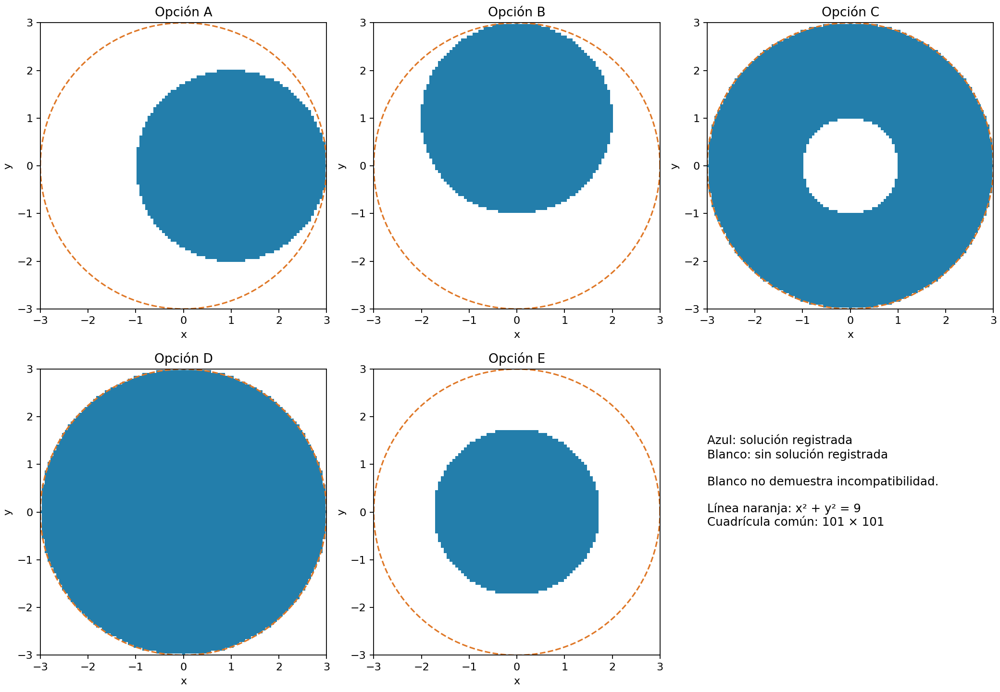

In [ ]:
archivos_mapas = []
if all(nombre in globals() for nombre in ("mapas", "xs", "ys")):
    archivos_mapas = graficar_mapas(mapas, xs, ys)
    from IPython.display import Image, display
    display(Image(filename=str(archivos_mapas[-1])))
else:
    print("Parte de Jared pendiente. Fase III sin representar.")


### 14.3. Resultados de la verificación y de los mapas

**Coincidencia con la teoría.** Las cinco matrices numéricas coinciden celda por celda con los criterios geométricos de la sección 13. No hay ninguna celda con solución teórica y valor 0, ni ninguna con valor 1 fuera de la región teórica.

| Opción | Celdas con solución | Fracción de las celdas con $r\le3$ | Iteraciones (media / máx.) |
|---|---|---|---|
| A | 3 495 | 44.6 % | 8.8 / 40 |
| B | 3 495 | 44.6 % | 9.2 / 45 |
| C | 6 968 | 88.8 % | 9.9 / 49 |
| D | 7 845 | 100 % | 11.6 / 50 |
| E | 2 617 | 33.4 % | 9.2 / 49 |

Las regiones obtenidas son las predichas. A y B son discos de radio 2 centrados en $(1,0)$ y $(0,1)$, con igual número de celdas porque B es A rotada $90^\circ$. C es el anillo $1\le r\le3$. D conserva todo el disco $r\le3$. E es el disco $r\le\sqrt3$. Ninguna opción excepto D conserva el alcance completo.

**Puntos de verificación.** Los quince casos se clasificaron según lo esperado: cinco interiores resueltos, cinco fronterizos resueltos, cuatro exteriores incompatibles y el exterior de D fuera del alcance. La diferencia principal está en la velocidad de convergencia. En los puntos interiores bastaron entre 6 y 9 iteraciones. En los puntos de frontera se necesitaron entre 15 y 28, y $\lvert\det J\rvert$ en la solución es del orden de $10^{-5}$, porque en la frontera los dos primeros eslabones (o el brazo equivalente) quedan alineados.

En el punto fronterizo $(0,\sqrt3)$ de la opción A, después de una fase inicial, el residuo se divide aproximadamente entre 4 en cada iteración:

$$3.4\times10^{-3},\ 8.5\times10^{-4},\ 2.1\times10^{-4},\ \dots,\ 2.0\times10^{-10},\ 5.0\times10^{-11}.$$

Esta es convergencia lineal y no cuadrática. Es el comportamiento típico de Newton-Raphson cuando el jacobiano es singular en la raíz (sección 7.4).

En las verificaciones de A y B, la celda más cercana al punto fronterizo vale 0. Esto se debe a que el punto de la cuadrícula más cercano, por ejemplo $(0,1.74)$ para A, queda justo fuera de la región. No es un fallo del método.

### 14.4. Limitaciones numéricas de la Fase III

1. **Resolución.** Con separación de $0.06$, las fronteras aparecen escalonadas y cada celda representa solo su punto central. Un objetivo compatible situado entre nodos de la cuadrícula no se evalúa, y una región de ancho menor que la separación podría no aparecer. Las áreas deducidas al contar celdas son aproximaciones.

2. **Singularidades.** En las fronteras de todas las regiones el jacobiano es singular en la solución, y la convergencia pasa de cuadrática a lineal. Con el máximo de 50 iteraciones todos los puntos convergieron, pero el margen fue pequeño: en D, una celda necesitó exactamente 50 iteraciones, y en C y E, 49. Con un máximo menor o una tolerancia más estricta, algunas celdas de frontera habrían quedado en 0 aun siendo compatibles. D es la opción con mayor promedio de iteraciones (11.6), lo que es coherente con sus singularidades adicionales en el interior (sección 7.4) y con que la suposición por defecto, común a todos los puntos, suele estar lejos de la solución.

3. **Falta de convergencia.** Un 0 solo significa que ninguna de las 17 suposiciones convergió. En este experimento coincide con la incompatibilidad geométrica en todas las celdas. Esa coincidencia la confirman los criterios de la sección 13, no el procedimiento numérico por sí solo. Con otras longitudes, otras suposiciones o regiones más complejas, un 0 podría corresponder a un punto compatible.

4. **Tolerancia y redondeo.** Los criterios geométricos usan una tolerancia de $10^{-9}$ en las desigualdades, y el método usa $10^{-10}$ en el residuo. Los puntos que están exactamente en una frontera, como $(\pm3,0)$ y $(0,\pm3)$ en C y D, dependen de esas tolerancias y del redondeo de las coordenadas de la cuadrícula.

5. **Costo.** La Alternativa 1 resuelve 10 201 sistemas por opción, con hasta 17 intentos cada uno. Vectorizar las iteraciones reduce el tiempo a pocos segundos, pero el costo crece con el cuadrado del número de puntos por eje: duplicar la resolución multiplica el trabajo por cuatro.

## 15. Resultados ordenados en radianes y grados

Los ángulos mostrados son las soluciones del solver, sin normalizarlos ni alterar su residuo. Un punto fallido conserva celdas de ángulos vacías (`NaN`); la postura retenida para animarlo se registra por separado. Las cifras en pantalla se redondean a ocho decimales, mientras los CSV conservan su precisión.


In [ ]:
from IPython.display import display, Image, Markdown
colecciones = [("Fase I", resultados_I), ("Fase II", resultados_II)]
columnas = ["punto", "x", "y", "estado", "theta1_rad", "theta2_rad", "theta3_rad",
            "theta1_deg", "theta2_deg", "theta3_deg", "iteraciones", "residuo"]
tablas = []
for nombre, resultados in colecciones:
    for opcion, r in resultados.items():
        display(Markdown(f"### {nombre} - Opción {opcion}"))
        display(r["tabla"][columnas].style.format(precision=8, na_rep="Sin solución"))
        display(r["tramos"].style.format(precision=6))
        tablas.append(r["tabla"])
if tablas:
    tabla_completa = pd.concat(tablas, ignore_index=True)
    tabla_completa.to_csv(CARPETA / "Resultados_radianes_grados.csv", index=False, encoding="utf-8-sig")
else:
    print("Sin resultados disponibles para tabular.")


### Fase I - Opción A

,punto,x,y,estado,theta1_rad,theta2_rad,theta3_rad,theta1_deg,theta2_deg,theta3_deg,iteraciones,residuo
0,1,1.50000000,0.50000000,exito,1.99482737,-2.41885841,0.42403104,114.29518895,-138.59037789,24.29518895,18,0.00000000
1,2,0.50000000,1.50000000,exito,2.55160492,-1.31811607,-1.23348885,146.19619273,-75.52248781,-70.67370492,8,0.00000000
2,3,-0.50000000,1.20000000,exito,2.74896729,-0.56423116,-2.18473613,157.50422381,-32.32806412,-125.17615968,6,0.00000000
3,4,1.20000000,-0.50000000,exito,0.10788363,-2.59634717,2.48846353,6.18127688,-148.75973478,142.57845791,7,0.00000000


,tramo,longitud,max_paso_angular_rad
0,Punto 1: alcanzado,1.906107,0.090632
1,Punto 2: alcanzado,1.585219,0.062105
2,Punto 3: alcanzado,1.076443,0.035642
3,Punto 4: alcanzado,3.260004,0.098958
4,"Regreso: postura (0, 0, 0)",6.091989,0.142183


### Fase I - Opción B

,punto,x,y,estado,theta1_rad,theta2_rad,theta3_rad,theta1_deg,theta2_deg,theta3_deg,iteraciones,residuo
0,1,1.50000000,0.50000000,exito,0.33730748,-1.31811607,2.55160492,19.32629509,-75.52248782,146.19619273,5,0.00000000
1,2,0.50000000,1.50000000,exito,-0.42403104,2.41885841,-0.42403104,-24.29518895,138.59037789,-24.29518895,9,0.00000000
2,3,-0.50000000,1.20000000,exito,-2.22392545,-2.59634717,0.10788363,-127.42154209,-148.75973478,6.18127688,7,0.00000000
3,4,1.20000000,-0.50000000,exito,-0.61393980,-0.56423116,2.74896729,-35.17615968,-32.32806412,157.50422381,19,0.00000000


,tramo,longitud,max_paso_angular_rad
0,Punto 1: alcanzado,1.709226,0.095605
1,Punto 2: alcanzado,7.725914,0.111493
2,Punto 3: alcanzado,1.318182,0.067440
3,Punto 4: alcanzado,7.943079,0.098958
4,"Regreso: postura (0, 0, 0)",1.875019,0.103000


... (20 outputs left out)

,tramo,longitud,max_paso_angular_rad
0,Punto 1: alcanzado,3.062136,0.093791
1,Punto 2: alcanzado,1.131371,0.021716
2,Punto 3: alcanzado,6.268668,0.093349
3,Punto 4: alcanzado,2.853062,0.074675
4,"Regreso: postura (0, 0, 0)",12.169090,0.133774


### Fase II - Opción E

,punto,x,y,estado,theta1_rad,theta2_rad,theta3_rad,theta1_deg,theta2_deg,theta3_deg,iteraciones,residuo
0,1,0.50000000,0.50000000,exito,-1.08165675,1.82347658,1.61437465,-61.97436641,104.47751219,92.49685422,7,0.00000000
1,2,1.30000000,1.30000000,incompatible,Sin solución,Sin solución,Sin solución,Sin solución,Sin solución,Sin solución,50,0.09428460
2,3,-1.40000000,0.30000000,exito,2.82986823,-1.01808121,2.68950863,162.13950631,-58.33175675,154.09749336,12,0.00000000
3,4,0.30000000,-1.40000000,exito,-2.47841529,1.01808121,1.67142741,-142.00273628,58.33175675,95.76573661,9,0.00000000


,tramo,longitud,max_paso_angular_rad
0,Punto 1: alcanzado,2.947781,0.068323
1,Punto 2: incompatible,0.000000,0.000000
2,Punto 3: alcanzado,5.362045,0.106470
3,Punto 4: alcanzado,3.174653,0.076292
4,"Regreso: postura (0, 0, 0)",3.718617,0.092863


## 16. Galería de gráficas y GIF

Los archivos se muestran en el mismo orden: Fase I A-E y Fase II A-E. La reproducción de GIF puede reiniciarse según el visor; el archivo contiene el recorrido completo de inicio a regreso.


### Fase I - Opción A

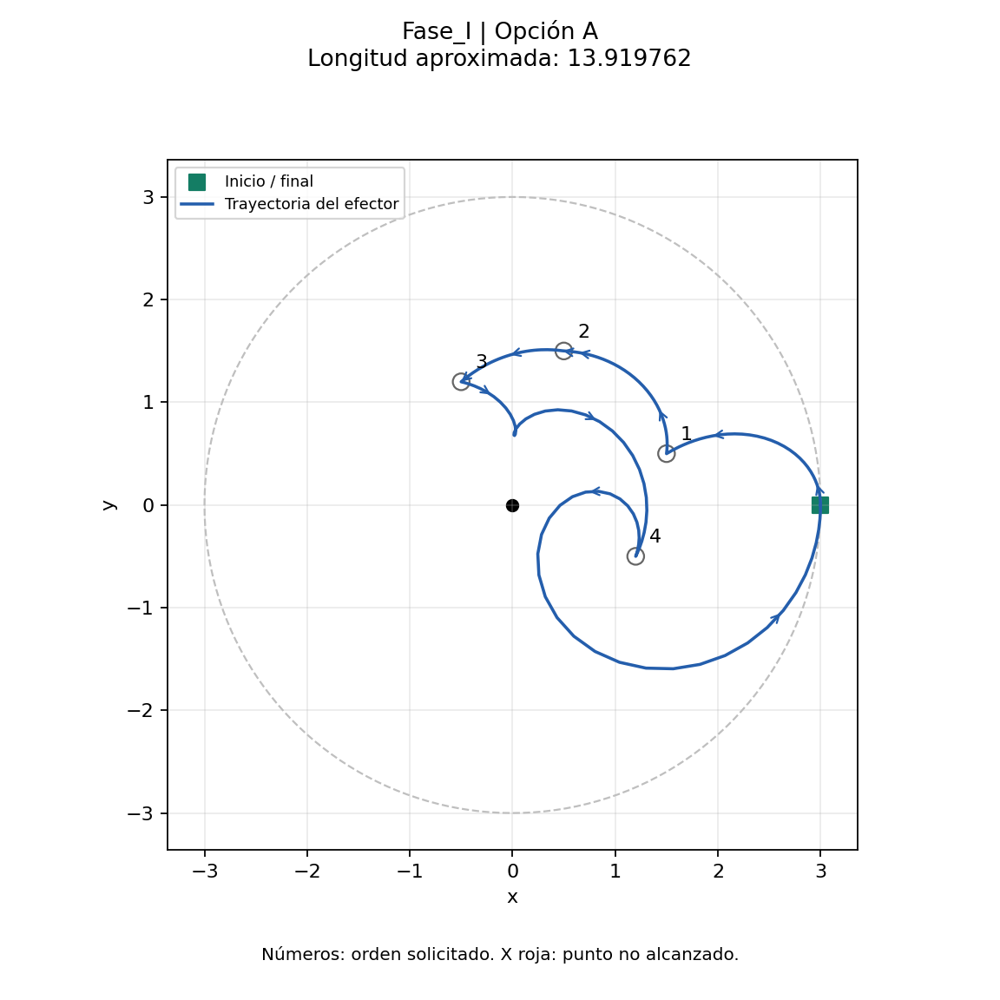

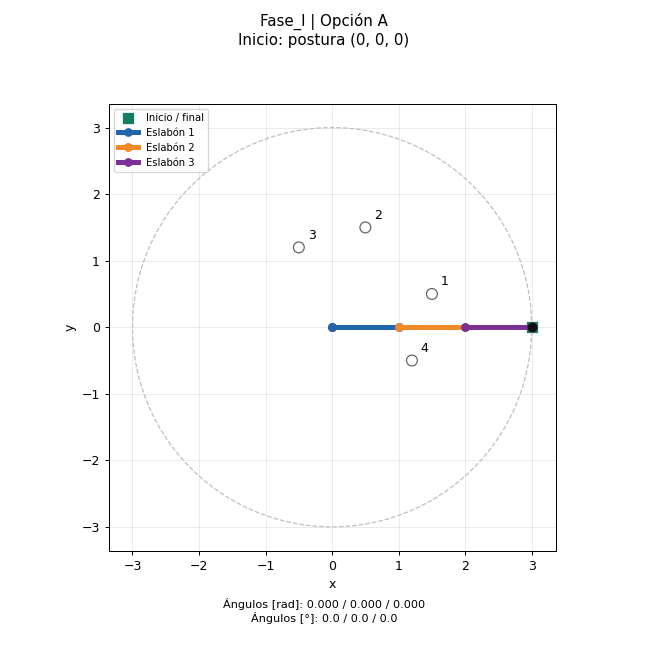

### Fase I - Opción B

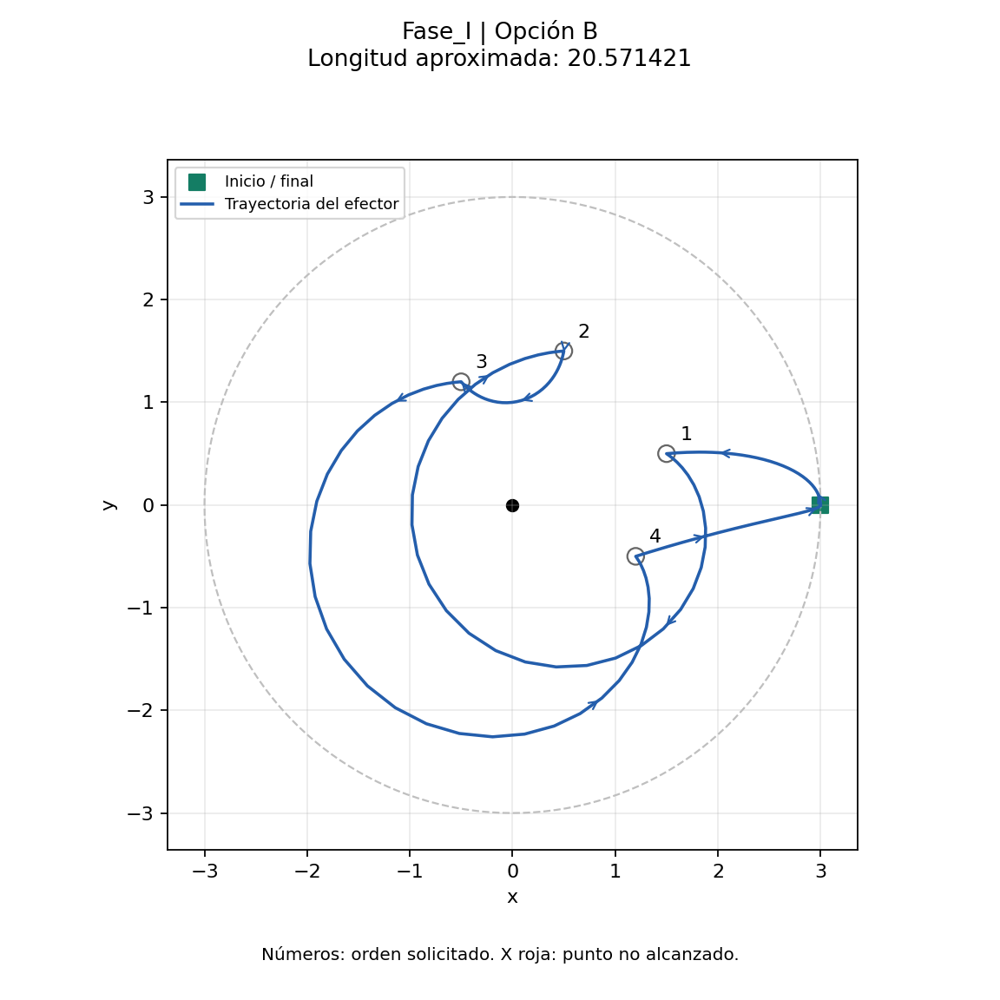

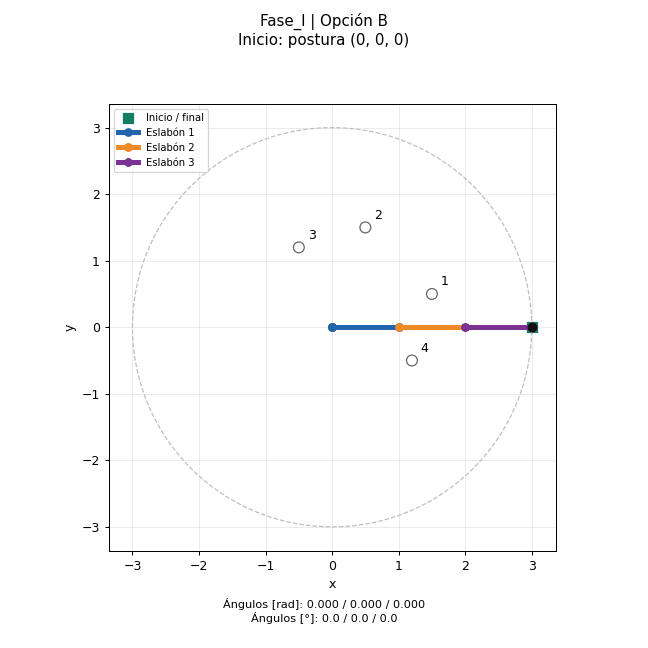

### Fase I - Opción C

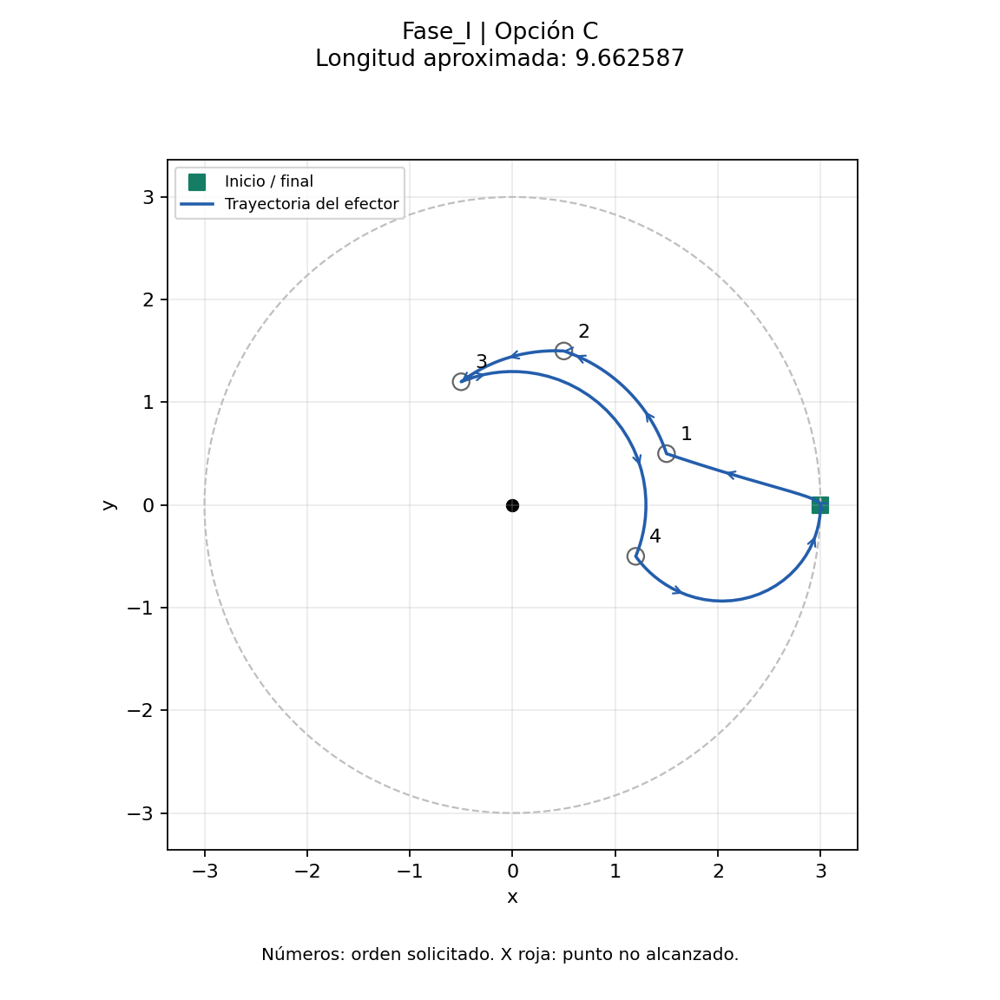

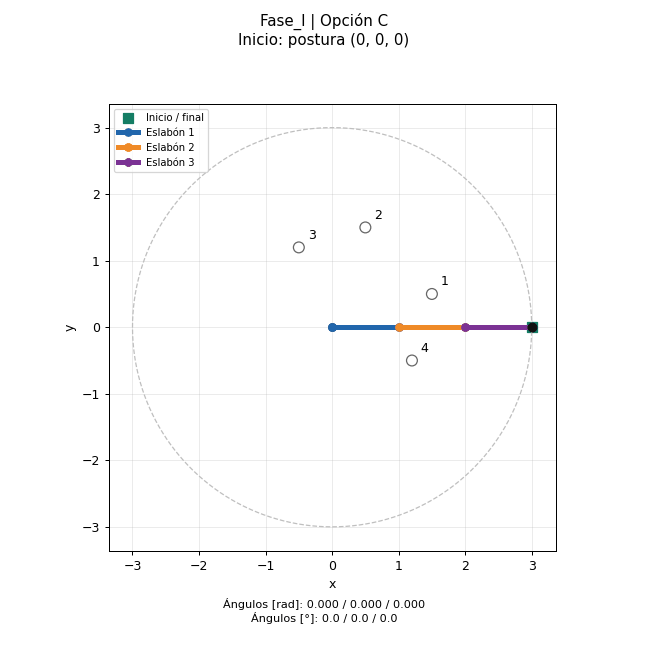

### Fase I - Opción D

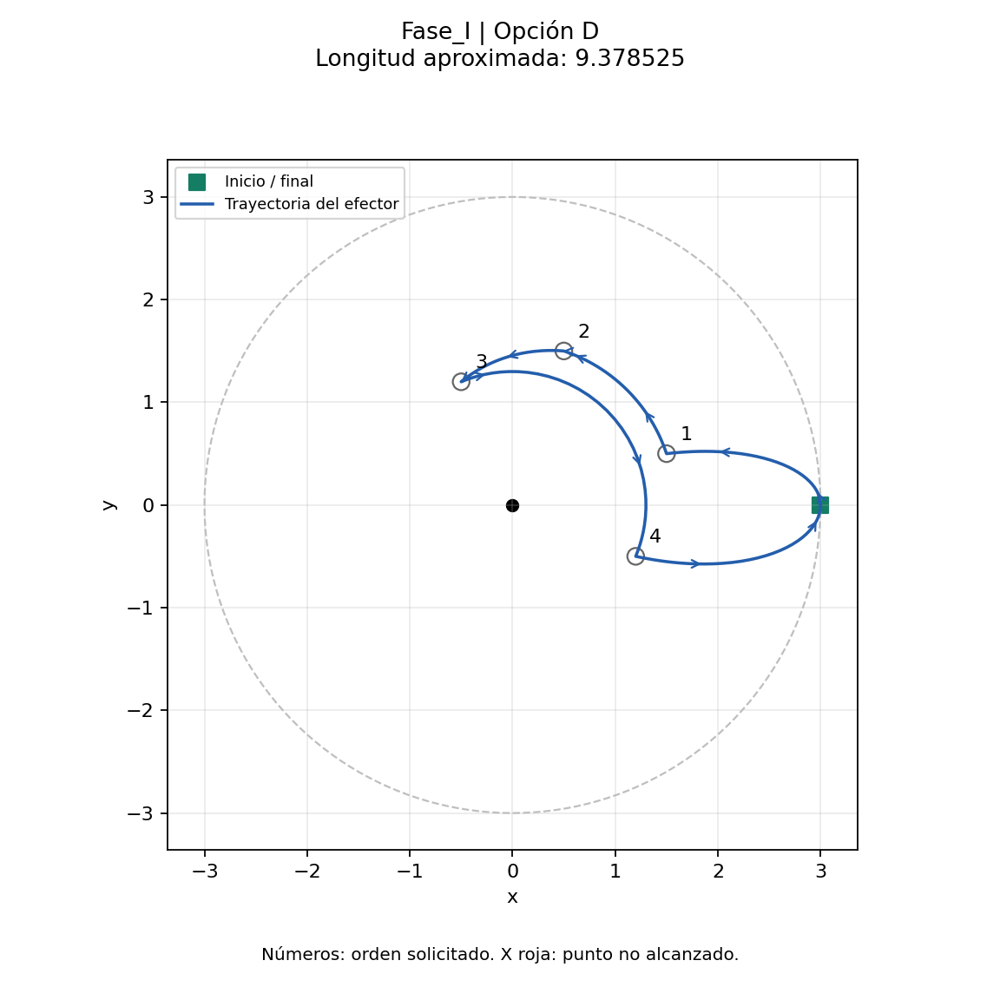

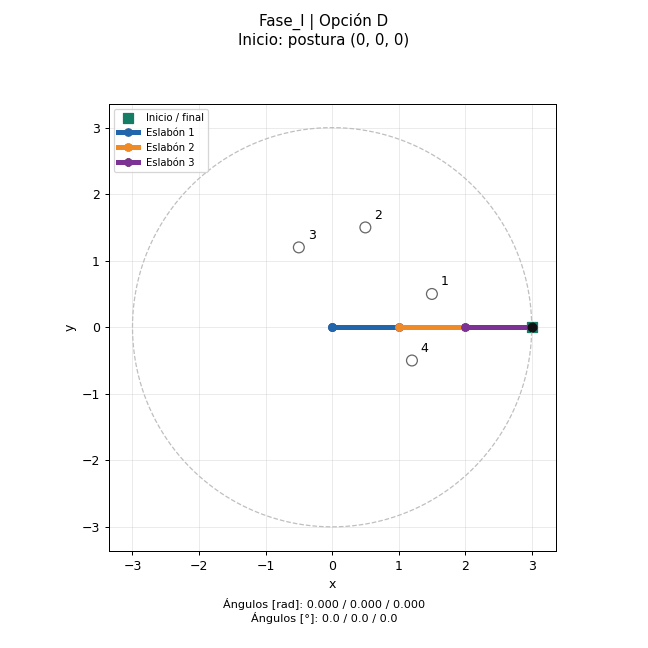

### Fase I - Opción E

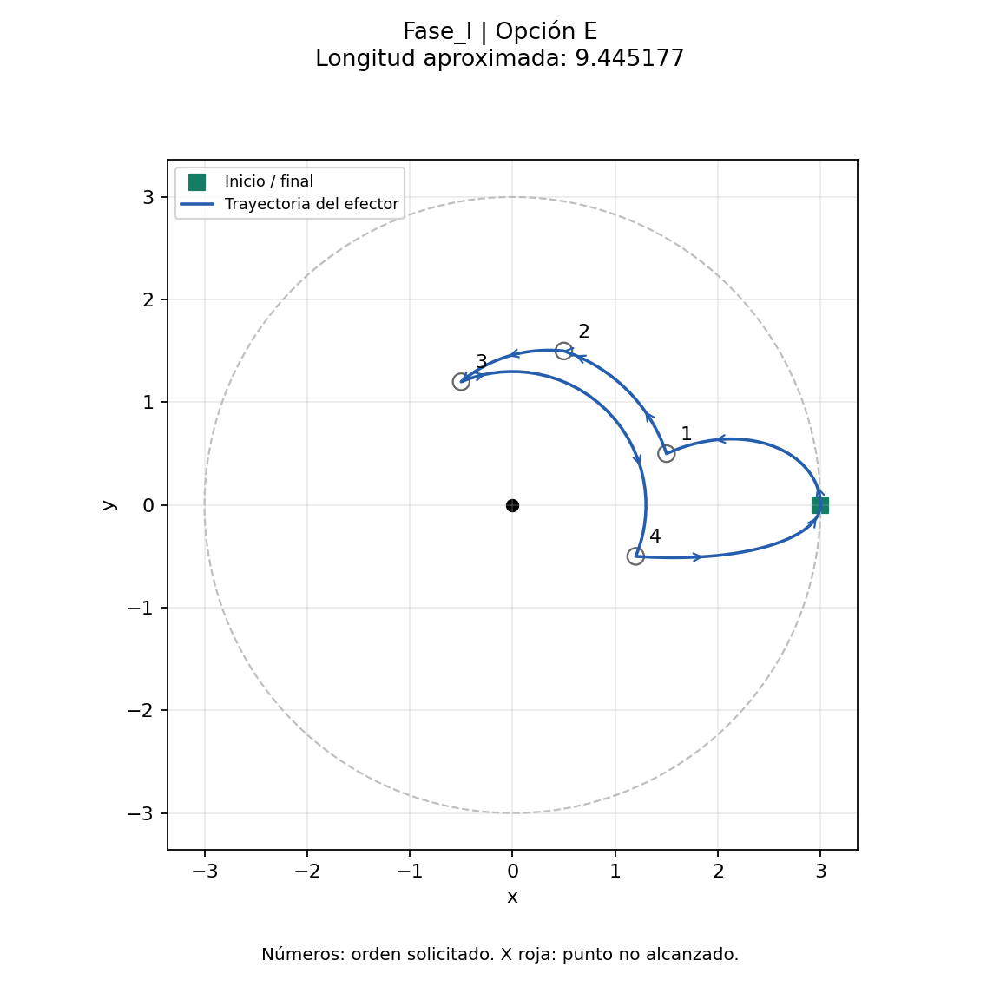

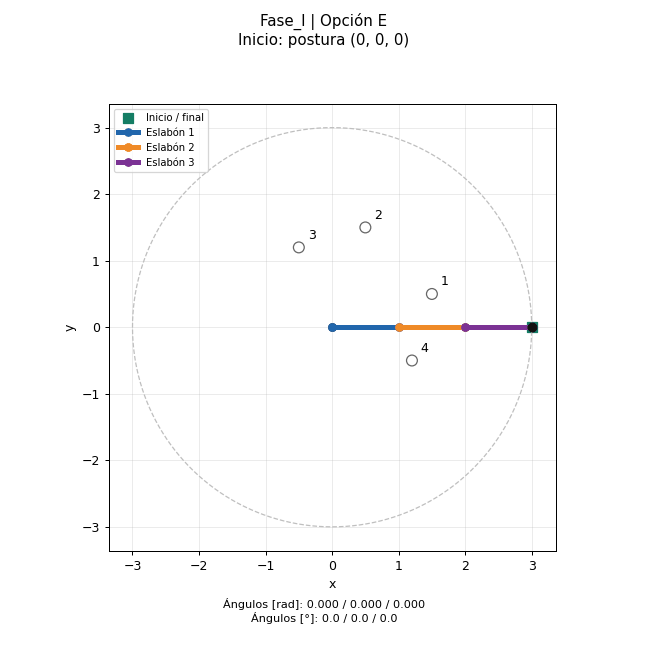

### Fase II - Opción A

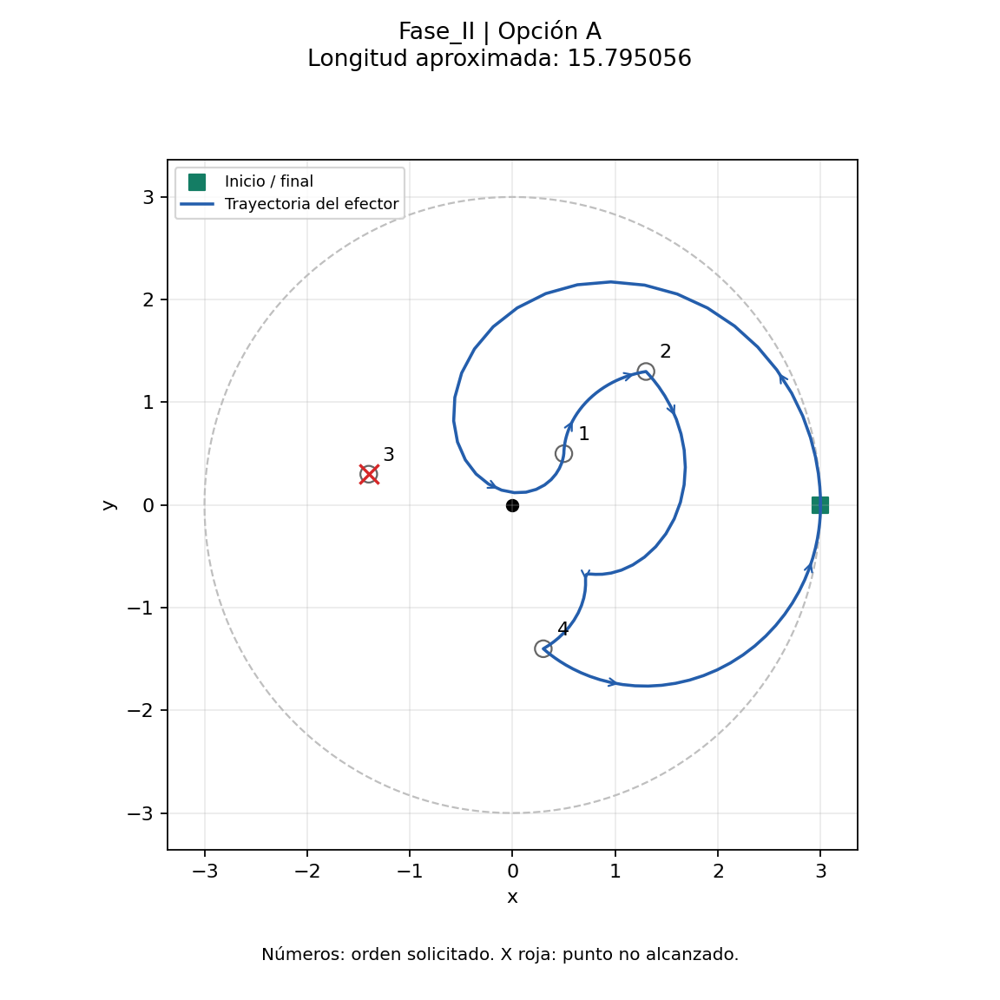

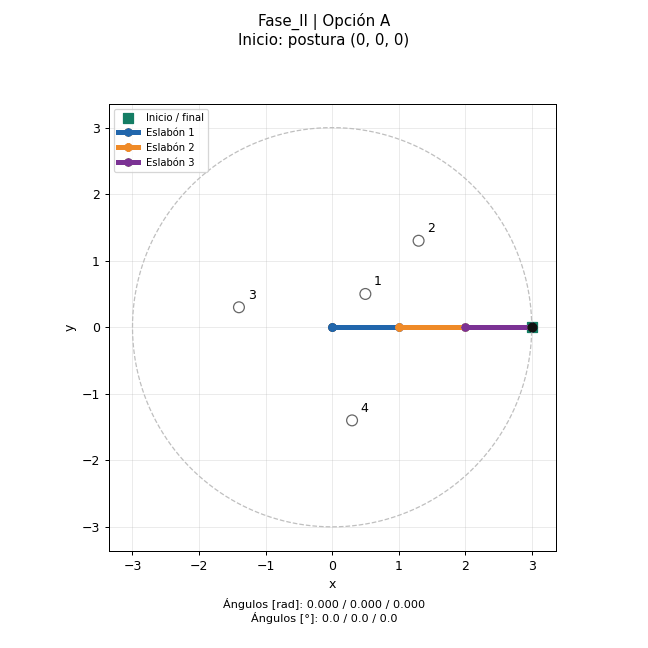

### Fase II - Opción B

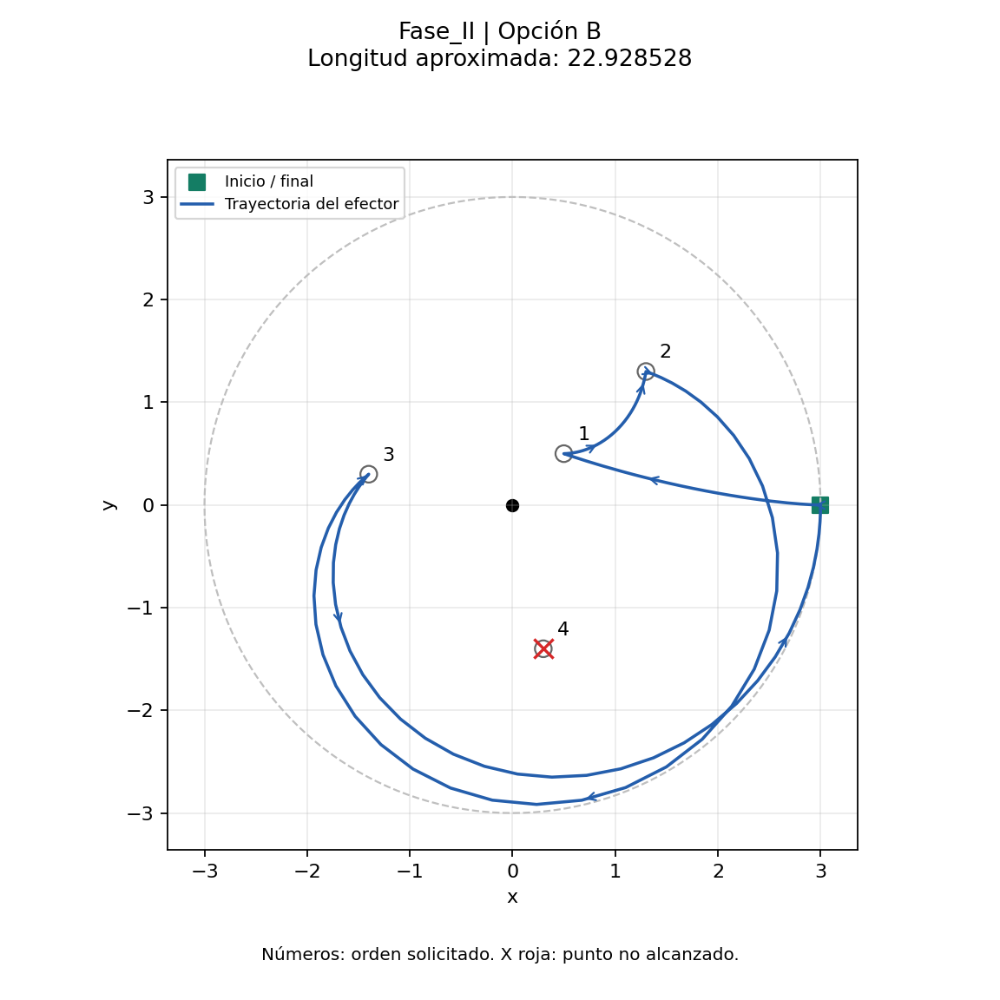

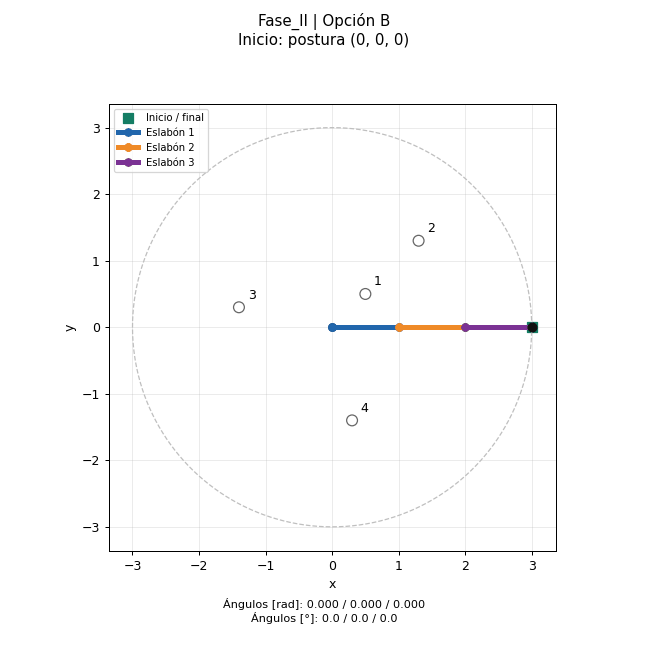

### Fase II - Opción C

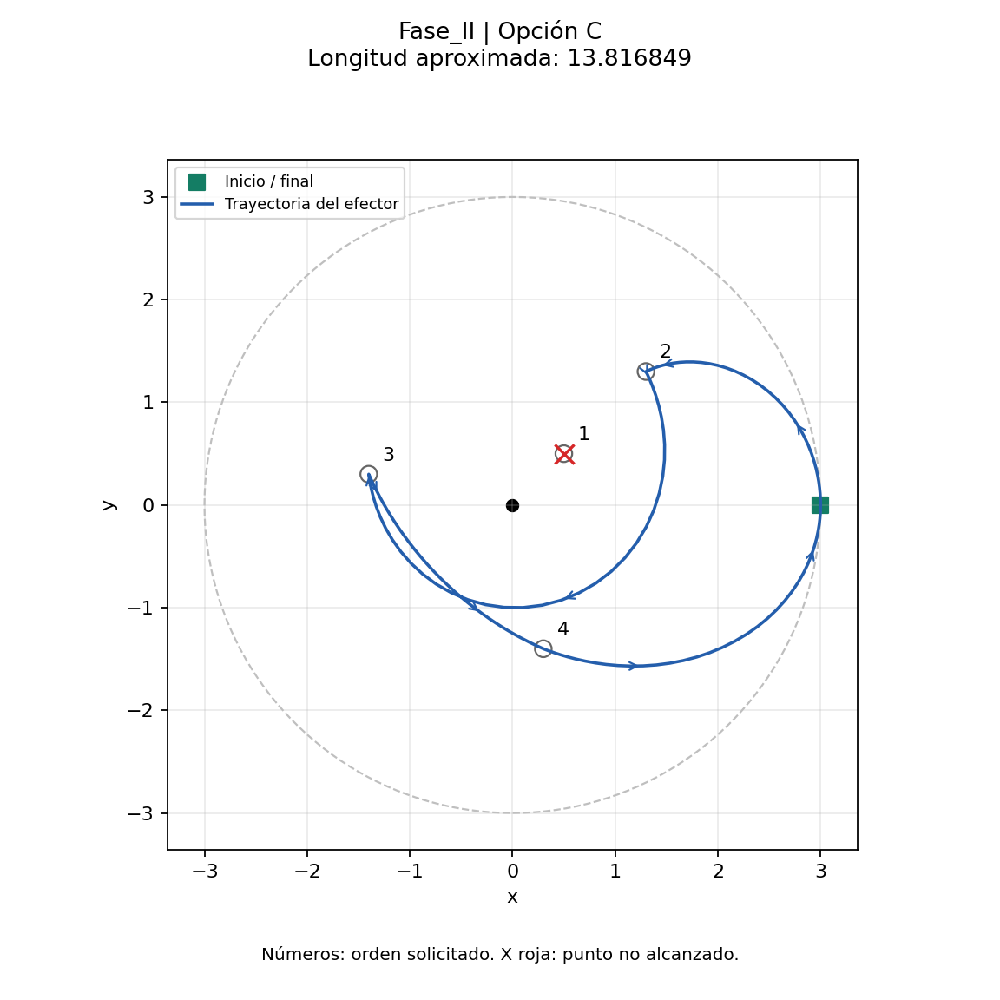

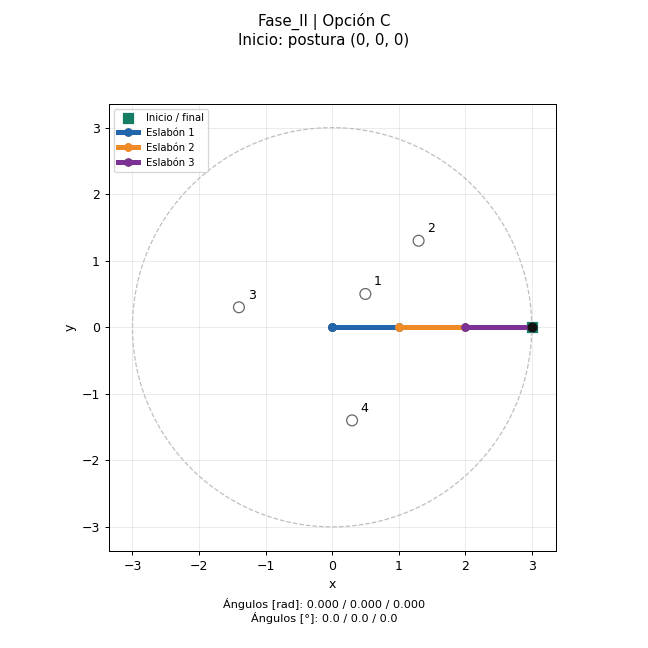

### Fase II - Opción D

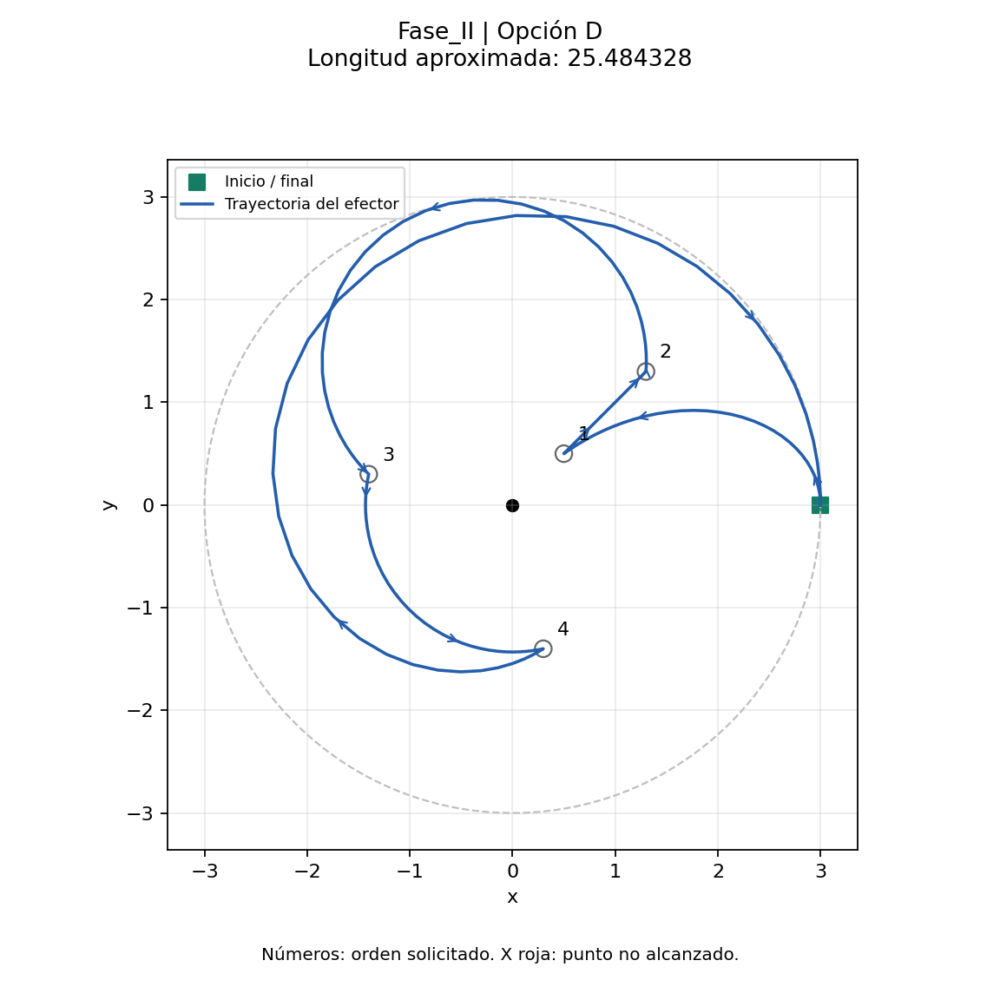

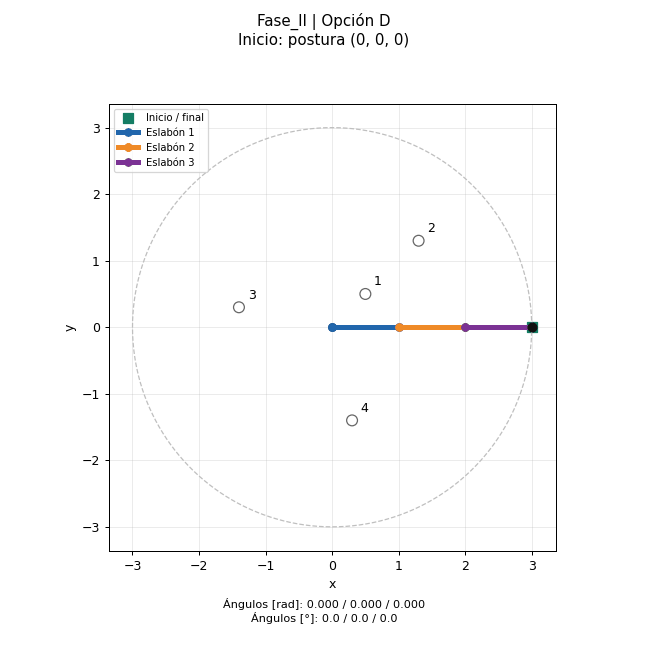

### Fase II - Opción E

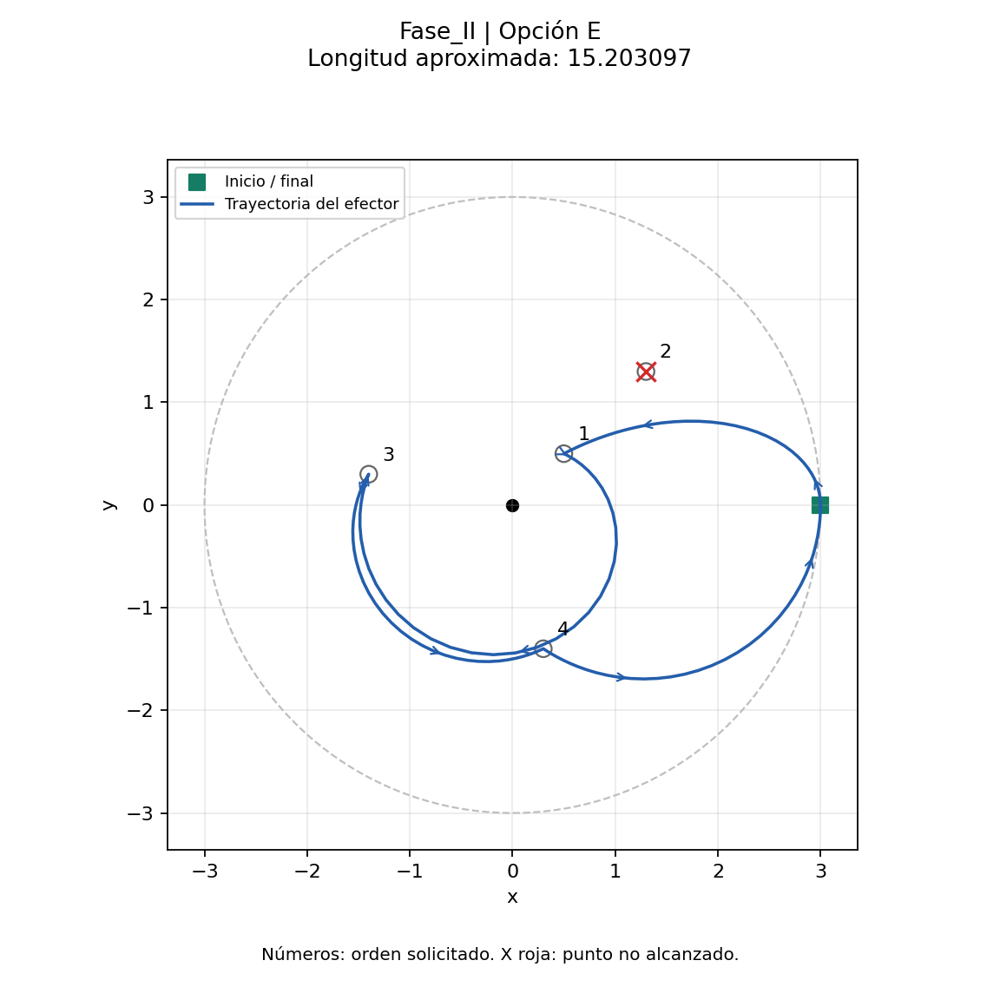

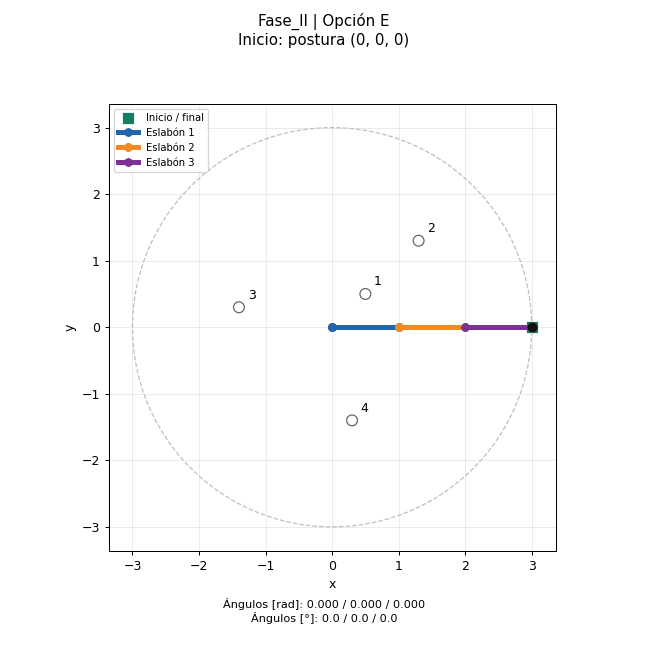

In [ ]:
for nombre, resultados in colecciones:
    for opcion, r in resultados.items():
        display(Markdown(f"### {nombre} - Opción {opcion}"))
        display(Image(filename=str(r["archivos"]["png"]), width=620))
        display(Image(filename=str(r["archivos"]["gif"])))
if not any(resultados for _, resultados in colecciones):
    print("Sin gráficas ni animaciones disponibles.")


### Verificación de resultados

Se comprueban las configuraciones inicial y final, las longitudes de los eslabones, el número de objetivos procesados, la longitud del recorrido y la existencia de los archivos exportados.

La revisión visual comprende la legibilidad de los rótulos, la visibilidad del rastro y la correspondencia entre los objetivos fallidos y sus marcas. La validación completa requiere ejecutar el cuaderno en un entorno limpio con las funciones y matrices correspondientes.


In [ ]:
for _, resultados in colecciones:
    for opcion, r in resultados.items():
        assert np.array_equal(r["angulos"][0], np.zeros(3))
        assert np.array_equal(r["angulos"][-1], np.zeros(3))
        assert len(r["tabla"]) == len(r["puntos"])
        assert np.allclose(r["xy"][[0, -1]], [[3, 0], [3, 0]])
        assert np.allclose(np.linalg.norm(np.diff(r["articulaciones"], axis=1), axis=2), r["L"])
        assert np.isclose(r["tramos"].longitud.sum(), r["longitud_total"])
        assert all(Path(p).exists() for p in r["archivos"].values())
        print(f"{r['fase']} {opcion}: extremos, eslabones, orden y archivos verificados.")


Fase_I A: extremos, eslabones, orden y archivos verificados.
Fase_I B: extremos, eslabones, orden y archivos verificados.
Fase_I C: extremos, eslabones, orden y archivos verificados.
Fase_I D: extremos, eslabones, orden y archivos verificados.
Fase_I E: extremos, eslabones, orden y archivos verificados.
Fase_II A: extremos, eslabones, orden y archivos verificados.
Fase_II B: extremos, eslabones, orden y archivos verificados.
Fase_II C: extremos, eslabones, orden y archivos verificados.
Fase_II D: extremos, eslabones, orden y archivos verificados.
Fase_II E: extremos, eslabones, orden y archivos verificados.


### Exportación de resultados
Los archivos del directorio `resultados_luis` se agrupan en un archivo ZIP. El directorio debe contener los resultados correspondientes a la ejecución que se desea exportar.


In [ ]:
if CARPETA.exists() and any(CARPETA.iterdir()):
    import shutil
    archivo_zip = shutil.make_archive("Resultados_Luis_Brazo3R", "zip", CARPETA)
    try:
        from google.colab import files
        files.download(archivo_zip)
    except ImportError:
        print("ZIP guardado en:", archivo_zip)
else:
    print("Sin resultados disponibles para exportar.")


NameError: name 'CARPETA' is not defined